# Final Project: Customer Experience at Olist

**Author:** Luciana Jost

**TripleTen Data Analyst Certification, final project**

**Date:** October 2026

**Interactive dashboard (Tableau Public):** https://public.tableau.com/views/OlistExperinciadoclienteeavaliaonegativa/PainelOlist

> **About this version:** this is the English translation of the original analysis, written in Portuguese. All text, tables and charts are in English and the results are identical to the original run. Variable names in the code and the keyword lists used to classify comments in section 4.4 are kept in Portuguese, because the customer comments in the dataset are written in Portuguese.

## 1. Introduction

This notebook carries out the analysis planned in the project decomposition, which was approved by the team lead.

**Project question:** which factors in the purchase journey reduce customer satisfaction at Olist, and which one weighs the most?

**Dataset:** Brazilian E-Commerce Public Dataset by Olist (Kaggle), with about 100 thousand orders placed between 2016 and 2018. The conclusions refer to the company's operating model in that period, not necessarily to how it operates today.

**Hypotheses:**

- **H1:** among orders with a similar delivery time, those that arrive after the estimated date receive lower scores.
- **H2:** among late orders, scores are lower when the customer answers the survey before receiving the product.
- **H3:** each day of delay lowers the score more than each day of early delivery raises it.
- **H4:** in on-time deliveries, dissatisfaction is more related to the product than in late deliveries.

**Main indicator:** negative review rate, defined as the share of orders with a score of 1 or 2.

> **Running the notebook:** the notebook runs end to end with the files organized as follows:
>
> ```
> (notebook folder)/
> ├── olist_customer_experience_EN.ipynb
> ├── validacao_h4_amostra.csv      (manual classification used in section 4.4)
> └── dados/                        (7 Olist tables, compressed CSV)
> ```
>
> The tables are stored as `.csv.gz` to keep the files small. pandas reads this format directly, without unzipping. The library versions used are listed in section 1.1.

### Structure of the analysis

1. Introduction
2. Data preparation
3. Exploratory analysis
4. Hypothesis testing
5. Conclusions and recommendations
6. Deliverables and sources

### 1.1 Environment and dependencies

For reproducibility, the cell below records the versions of Python and of the libraries used to run this notebook. Apart from them, the analysis only uses modules from the Python standard library (`math`, `unicodedata` and `pathlib`).

| Library | Use in the project |
|---|---|
| pandas | reading, preparing and aggregating the data |
| matplotlib | charts and association model |
| scipy | statistical tests (z-test, Mann-Whitney, Fisher, linear regression) |


In [1]:
import sys

import matplotlib
import pandas
import scipy

print('Python:', sys.version.split()[0])
print('pandas:', pandas.__version__)
print('matplotlib:', matplotlib.__version__)
print('scipy:', scipy.__version__)

Python: 3.13.16
pandas: 3.0.5
matplotlib: 3.11.2
scipy: 1.18.1


## 2. Data preparation

### 2.1 Loading

The analysis uses seven of the nine tables in the dataset, the same ones described in the decomposition. The tables are read from the `dados/` folder, as compressed CSV files (`.csv.gz`).


In [2]:
import math
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyBboxPatch
from scipy import stats as st

PASTA = 'dados/'

orders = pd.read_csv(PASTA + 'olist_orders_dataset.csv.gz')
reviews = pd.read_csv(PASTA + 'olist_order_reviews_dataset.csv.gz')
items = pd.read_csv(PASTA + 'olist_order_items_dataset.csv.gz')
products = pd.read_csv(PASTA + 'olist_products_dataset.csv.gz')
sellers = pd.read_csv(PASTA + 'olist_sellers_dataset.csv.gz')
customers = pd.read_csv(PASTA + 'olist_customers_dataset.csv.gz')
categories = pd.read_csv(PASTA + 'product_category_name_translation.csv.gz')

tabelas = {
    'orders': orders,
    'reviews': reviews,
    'items': items,
    'products': products,
    'sellers': sellers,
    'customers': customers,
    'categories': categories
}

pd.DataFrame(
    [(nome, df.shape[0], df.shape[1]) for nome, df in tabelas.items()],
    columns=['table', 'rows', 'columns']
)

,table,rows,columns
0,orders,99441,8
1,reviews,99224,7
2,items,112650,7
3,products,32951,9
4,sellers,3095,4
5,customers,99441,5
6,categories,71,2


All seven tables were loaded with the same volumes described in the decomposition: 99,441 orders, 99,224 reviews and 112,650 items.

The preparation below carries out the nine steps planned in section 5.1 of the decomposition.

### 2.2 Converting dates

In the decomposition, the eight date columns in the dataset were identified as text. The cell below converts all of them to `datetime` and confirms the result.

In [3]:
COLUNAS_DE_DATA = {
    'orders': [
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
    ],
    'reviews': ['review_creation_date', 'review_answer_timestamp'],
    'items': ['shipping_limit_date'],
}

for nome, colunas in COLUNAS_DE_DATA.items():
    for coluna in colunas:
        tabelas[nome][coluna] = pd.to_datetime(tabelas[nome][coluna])

pd.DataFrame(
    [
        (nome, coluna, str(tabelas[nome][coluna].dtype))
        for nome, colunas in COLUNAS_DE_DATA.items()
        for coluna in colunas
    ],
    columns=['table', 'column', 'type'],
)

,table,column,type
0,orders,order_purchase_timestamp,datetime64[us]
1,orders,order_approved_at,datetime64[us]
2,orders,order_delivered_carrier_date,datetime64[us]
3,orders,order_delivered_customer_date,datetime64[us]
4,orders,order_estimated_delivery_date,datetime64[us]
5,reviews,review_creation_date,datetime64[us]
6,reviews,review_answer_timestamp,datetime64[us]
7,items,shipping_limit_date,datetime64[us]


The eight date columns were converted to `datetime`, which makes it possible to calculate time intervals between the stages of an order.

### 2.3 Selecting delivered orders

The analysis depends on comparing the delivery date with the promised date, so it only considers orders with status `delivered` and a recorded delivery date. This filter also removes the 14 orders with inconsistent status and date identified in the decomposition.

In [4]:
pedidos = orders[
    (orders['order_status'] == 'delivered')
    & orders['order_delivered_customer_date'].notna()
].copy()

print('Orders in the dataset:', len(orders))
print('Delivered orders with a delivery date:', len(pedidos))
print('Excluded orders:', len(orders) - len(pedidos))

Orders in the dataset: 99441
Delivered orders with a delivery date: 96470
Excluded orders: 2971


Of the 99,441 orders, 96,470 were delivered and have a recorded delivery date. The 2,971 excluded orders are those that never reached the customer (canceled, in transit, unavailable and other statuses) plus 8 orders with status `delivered` but no delivery date.

### 2.4 One review per order

In the decomposition, 547 orders had more than one review. To keep a single score per order, the cell below keeps the review answered last, which reflects the customer's final perception. It then joins the reviews to the delivered orders. Orders without a review are excluded, since they have no satisfaction measure.

In [5]:
avaliacoes = (
    reviews.sort_values('review_answer_timestamp')
    .drop_duplicates(subset='order_id', keep='last')
)

pedidos_avaliados = pedidos.merge(avaliacoes, on='order_id', how='inner')

print('Reviews in the dataset:', len(reviews))
print('Reviews after keeping one per order:', len(avaliacoes))
print('Delivered and reviewed orders:', len(pedidos_avaliados))
print('Delivered orders without a review (excluded):', len(pedidos) - len(pedidos_avaliados))

Reviews in the dataset: 99224
Reviews after keeping one per order: 98673
Delivered and reviewed orders: 95824
Delivered orders without a review (excluded): 646


- Of the 99,224 reviews, 98,673 remain after keeping one per order. 551 reviews were removed, slightly more than the number of affected orders (547), because some orders had three reviews.
- 95,824 delivered orders have a review and form the base of the satisfaction analysis.
- 646 delivered orders have no review and were excluded.

### 2.5 Aggregating items per order

The `items` table has one row per item sold, while the unit of analysis is the order. The cell below summarizes each order's items in a single row, with the number of items, the number of distinct sellers, the total product value, the total freight value and the main category. The main category is the category of the order's first item.

In [6]:
itens_com_categoria = items.merge(
    products[['product_id', 'product_category_name']], on='product_id', how='left'
)

resumo_itens = (
    itens_com_categoria.groupby('order_id')
    .agg(
        numero_de_itens=('order_item_id', 'count'),
        numero_de_vendedores=('seller_id', 'nunique'),
        valor_produtos=('price', 'sum'),
        valor_frete=('freight_value', 'sum'),
    )
    .reset_index()
)

categoria_principal = (
    itens_com_categoria.sort_values('order_item_id')
    .drop_duplicates(subset='order_id')
    [['order_id', 'product_category_name']]
)

resumo_itens = resumo_itens.merge(categoria_principal, on='order_id', how='left')

print('Orders with items:', len(resumo_itens))
display(resumo_itens['numero_de_vendedores'].value_counts().sort_index().to_frame('orders'))
resumo_itens.head()

Orders with items: 98666


,orders
numero_de_vendedores,
1,97388
2,1219
3,54
4,3
5,2


,order_id,numero_de_itens,numero_de_vendedores,valor_produtos,valor_frete,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,1,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,1,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,1,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,199.90,18.14,ferramentas_jardim


- 98,666 orders have items recorded. The difference from the 99,441 orders in the dataset corresponds to orders without items, such as canceled or unavailable ones, which were already left out by the selection in section 2.3.
- 97,388 orders (98.7%) have a single seller. The remaining 1,278 orders (1.3%) involve two to five sellers and may reach the customer in separate deliveries. This group is examined in the complementary analysis of H4.

### 2.6 Single analytical table

The cell below joins the reviewed orders to the item summary and to the customer's state, creating a table with one row per order. It then checks whether the join created duplicated orders or missing information.

In [7]:
base = (
    pedidos_avaliados
    .merge(resumo_itens, on='order_id', how='left')
    .merge(customers[['customer_id', 'customer_state']], on='customer_id', how='left')
)

print('Rows in the table:', len(base))
print('Duplicated orders:', base['order_id'].duplicated().sum())
print('Orders without items:', base['numero_de_itens'].isna().sum())
print('Orders without customer state:', base['customer_state'].isna().sum())

Rows in the table: 95824
Duplicated orders: 0
Orders without items: 0
Orders without customer state: 0


The table has 95,824 rows, one per delivered and reviewed order. The join created no duplicated orders, and every order has its item summary and customer state.

### 2.7 Derived variables

The cell below creates the variables planned in the decomposition:

| Variable | Definition |
|---|---|
| `tempo_entrega_dias` | Delivery time: days between purchase and delivery to the customer |
| `diferenca_prazo_dias` | Days between the delivery date and the estimated date. Negative values mean early delivery and positive values mean delay |
| `fora_do_prazo` | Late: true when delivery happens on a day after the estimated date |
| `avaliacao_negativa` | Negative review: true when the score is 1 or 2 |
| `avaliacao_antes_da_entrega` | Reviewed before delivery: true when the customer answered the survey before receiving the product |

The estimated delivery date is recorded without a time. For this reason, the difference from the promised date is calculated in whole days, comparing the delivery date with the estimated date: an order delivered on the estimated day itself is considered on time.

The comment topic variable, used in H4, is created in the corresponding section.

In [8]:
SEGUNDOS_POR_DIA = 86400

base['tempo_entrega_dias'] = (
    base['order_delivered_customer_date'] - base['order_purchase_timestamp']
).dt.total_seconds() / SEGUNDOS_POR_DIA

base['diferenca_prazo_dias'] = (
    base['order_delivered_customer_date'].dt.normalize()
    - base['order_estimated_delivery_date']
).dt.days

base['fora_do_prazo'] = base['diferenca_prazo_dias'] > 0
base['avaliacao_negativa'] = base['review_score'] <= 2
base['avaliacao_antes_da_entrega'] = (
    base['review_answer_timestamp'] < base['order_delivered_customer_date']
)

print(f"Late orders: {base['fora_do_prazo'].sum()} ({base['fora_do_prazo'].mean():.1%})")
print(f"Negative reviews: {base['avaliacao_negativa'].sum()} ({base['avaliacao_negativa'].mean():.1%})")

base[['tempo_entrega_dias', 'diferenca_prazo_dias']].describe().round(2)

Late orders: 6381 (6.7%)
Negative reviews: 12272 (12.8%)


,tempo_entrega_dias,diferenca_prazo_dias
count,95824.00,95824.00
mean,12.52,-11.91
std,9.46,10.11
min,0.53,-147.00
25%,6.76,-17.00
50%,10.21,-12.00
75%,15.66,-7.00
max,208.35,188.00


- **Delivery time:** the median is 10.2 days, and half of the orders arrive between 6.8 and 15.7 days after purchase. The mean (12.5 days) is higher than the median, which indicates a right skew: some orders take much longer than usual, with a maximum of 208 days.
- **Difference from the promised date:** the median is 12 days early. Three quarters of orders arrive at least 7 days before the estimated date. The extremes range from 147 days early to 188 days late.
- **Late deliveries:** 6,381 orders (6.7%) arrived after the estimated date.
- **Negative reviews:** 12,272 orders (12.8%) received a score of 1 or 2.

The estimated date given to the customer includes a wide buffer: in most orders, delivery happens well before the promise. The extreme values of both time variables are examined in the next section.

### 2.8 Extreme values and date consistency

The cell below shows the percentiles of the two time variables, to size the extreme values, and checks whether each order's dates follow the expected order of stages.

In [9]:
PERCENTIS = [0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999]

display(
    base[['tempo_entrega_dias', 'diferenca_prazo_dias']]
    .quantile(PERCENTIS)
    .round(1)
)

inconsistencias = pd.Series({
    'delivered to customer before purchase': (
        base['order_delivered_customer_date'] < base['order_purchase_timestamp']
    ).sum(),
    'approved before purchase': (
        base['order_approved_at'] < base['order_purchase_timestamp']
    ).sum(),
    'handed to carrier after delivery to customer': (
        base['order_delivered_carrier_date'] > base['order_delivered_customer_date']
    ).sum(),
})

inconsistencias.to_frame('orders')

,tempo_entrega_dias,diferenca_prazo_dias
0.001,1.1,-51.2
0.010,1.8,-36.0
0.050,3.0,-26.0
0.500,10.2,-12.0
0.950,29.1,3.0
0.990,45.9,18.0
0.999,81.1,54.0


,orders
delivered to customer before purchase,0
approved before purchase,0
handed to carrier after delivery to customer,23


**Extreme values:**

- **Delivery time:** 99% of orders arrive within 45.9 days, and 99.9% within 81.1 days. Cases above that are few and far from the 10.2-day median.
- **Difference from the promised date:** 99% of orders fall between 36 days early and 18 days late. In both directions, the extremes exceed 50 days.

**Date consistency:**

- No order has delivery or approval before the purchase.
- 23 orders have a carrier handover date later than the delivery date to the customer, which indicates an error in the handover date.

**Treatment:**

- Extreme values are kept. They are rare but plausible for a logistics operation shipping across the whole country, and the dates of these orders are consistent. Excluding them would remove precisely the longest delays, which matter for the analysis.
- The 23 orders with an inconsistent handover date are kept, because the carrier handover date is not used in any variable of the analysis.
- In analyses sensitive to extreme values, such as the line fitting in H3, the range of days considered is defined in that section, based on the number of orders available on each day.

### 2.9 Checking the final table

The cell below checks, in the columns used in the analysis, whether the final table has duplicated orders or missing values.

In [10]:
COLUNAS_DA_ANALISE = [
    'order_id',
    'review_score',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'review_answer_timestamp',
    'review_comment_message',
    'numero_de_itens',
    'numero_de_vendedores',
    'valor_produtos',
    'valor_frete',
    'product_category_name',
    'customer_state',
    'tempo_entrega_dias',
    'diferenca_prazo_dias',
    'fora_do_prazo',
    'avaliacao_negativa',
    'avaliacao_antes_da_entrega',
]

print('Orders in the final table:', len(base))
print('Duplicated orders:', base['order_id'].duplicated().sum())

ausentes = base[COLUNAS_DA_ANALISE].isna().sum()
ausentes[ausentes > 0].to_frame('missing')

Orders in the final table: 95824
Duplicated orders: 0


,missing
review_comment_message,56926
product_category_name,1350


**Reading the results**

The final table has **95,824 orders**, each appearing only once. Each row is therefore one delivered and reviewed order, which is the unit of analysis for all hypotheses.

Among the columns used in the analysis, only two have missing values:

- **`review_comment_message` (56,926 missing, 59.4%)**: the written comment is optional in the satisfaction survey, so a missing value means the customer gave a score without writing anything. It is not a recording error. **38,898 orders have a comment (40.6%)**. The column is kept as is and will only be used in H4, which depends on the text.
- **`product_category_name` (1,350 missing, 1.4%)**: products without a category in the catalog. These orders stay in the table, since they have a score and complete dates, and are only left out of the analyses by category.

**Preparation summary:** we started from 99,441 orders and arrived at 95,824 delivered and reviewed orders, with the variables for promised date, delay, negative review and review timing already calculated. The table is ready for exploratory analysis.

## 3. Exploratory analysis

### 3.1 Distribution of delivery time and of the difference from the promised date

Before comparing groups, we look at the shape of the two delivery variables: how long orders take to arrive and how far from the promised date they arrive. The difference from the promised date is measured in whole days: negative values mean early delivery, zero means delivery on the promised day and positive values mean delay.

Since both variables have long tails, the histograms show a window that covers almost the whole table (0 to 60 days for delivery time; −60 to +30 days for the difference). Orders outside this window are counted below the chart and remain in the table.

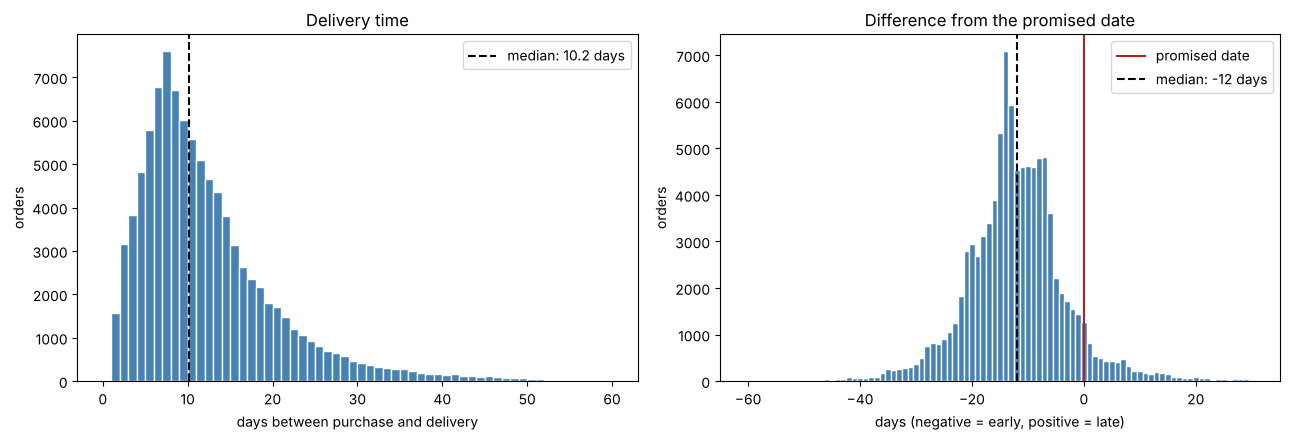

Orders outside the delivery time chart window: 291
Orders outside the difference chart window: 363

diferenca_prazo_dias
early                  88163
late                    6381
on the promised day     1280
Name: count, dtype: int64


In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))

# Delivery time (calendar days between purchase and delivery)
eixos[0].hist(base['tempo_entrega_dias'], bins=60, range=(0, 60), color='steelblue', edgecolor='white')
eixos[0].axvline(base['tempo_entrega_dias'].median(), color='black', linestyle='--',
                 label=f"median: {base['tempo_entrega_dias'].median():.1f} days")
eixos[0].set_title('Delivery time')
eixos[0].set_xlabel('days between purchase and delivery')
eixos[0].set_ylabel('orders')
eixos[0].legend()

# Difference from the promised date (one bin per whole day)
eixos[1].hist(base['diferenca_prazo_dias'], bins=91, range=(-60.5, 30.5), color='steelblue', edgecolor='white')
eixos[1].axvline(0, color='firebrick', linestyle='-', label='promised date')
eixos[1].axvline(base['diferenca_prazo_dias'].median(), color='black', linestyle='--',
                 label=f"median: {base['diferenca_prazo_dias'].median():.0f} days")
eixos[1].set_title('Difference from the promised date')
eixos[1].set_xlabel('days (negative = early, positive = late)')
eixos[1].set_ylabel('orders')
eixos[1].legend()

plt.tight_layout()
plt.show()

fora_janela_tempo = (base['tempo_entrega_dias'] > 60).sum()
fora_janela_diferenca = ((base['diferenca_prazo_dias'] < -60) | (base['diferenca_prazo_dias'] > 30)).sum()
print('Orders outside the delivery time chart window:', fora_janela_tempo)
print('Orders outside the difference chart window:', fora_janela_diferenca)
print()
print(base['diferenca_prazo_dias'].apply(
    lambda d: 'early' if d < 0 else ('on the promised day' if d == 0 else 'late')
).value_counts())

**Reading the results**

**Delivery time.** The distribution is right-skewed: most orders arrive between 5 and 10 days after purchase, the median is 10.2 days, and a long tail extends beyond 30 days. Only 291 orders (0.3%) took more than 60 days and fell outside the chart window.

**Difference from the promised date.** Early delivery is the dominant pattern:

| Situation | Orders | % of total |
|---|---|---|
| Early | 88,163 | 92.0% |
| On the promised day | 1,280 | 1.3% |
| Late | 6,381 | 6.7% |

The median is 12 days before the promised date, which shows that the promised delivery time is usually much longer than the actual delivery time. On the late side, most orders are concentrated in the first days after the promised date, and frequency drops quickly after that. Only 363 orders (0.4%) fell outside the −60 to +30 day window.

**Implications for the hypotheses:**

- **H1:** since delays are relatively rare (6.7%) and delivery time varies widely, the comparison between late and on-time orders must be made within delivery time bands, so that the effect of the delay is not confused with the effect of a long wait.
- **H3:** the table is very unbalanced between the two sides of the promised date. There are tens of thousands of early orders and few orders more than a few weeks late. For this reason, the window for comparing delay and early delivery will be defined by data density, avoiding days with few orders, where the average score is unstable.

### 3.2 Monthly trend of orders, delays and negative reviews

We group orders by purchase month, when the customer receives the promised date, and calculate three indicators per month: number of orders, late order rate (KPI5) and negative review rate (KPI1). The goal is twofold: identify months with very low volume, which would make the rates unstable and should be considered for the time cutoff, and check whether delay and negative review rates move together over the period.

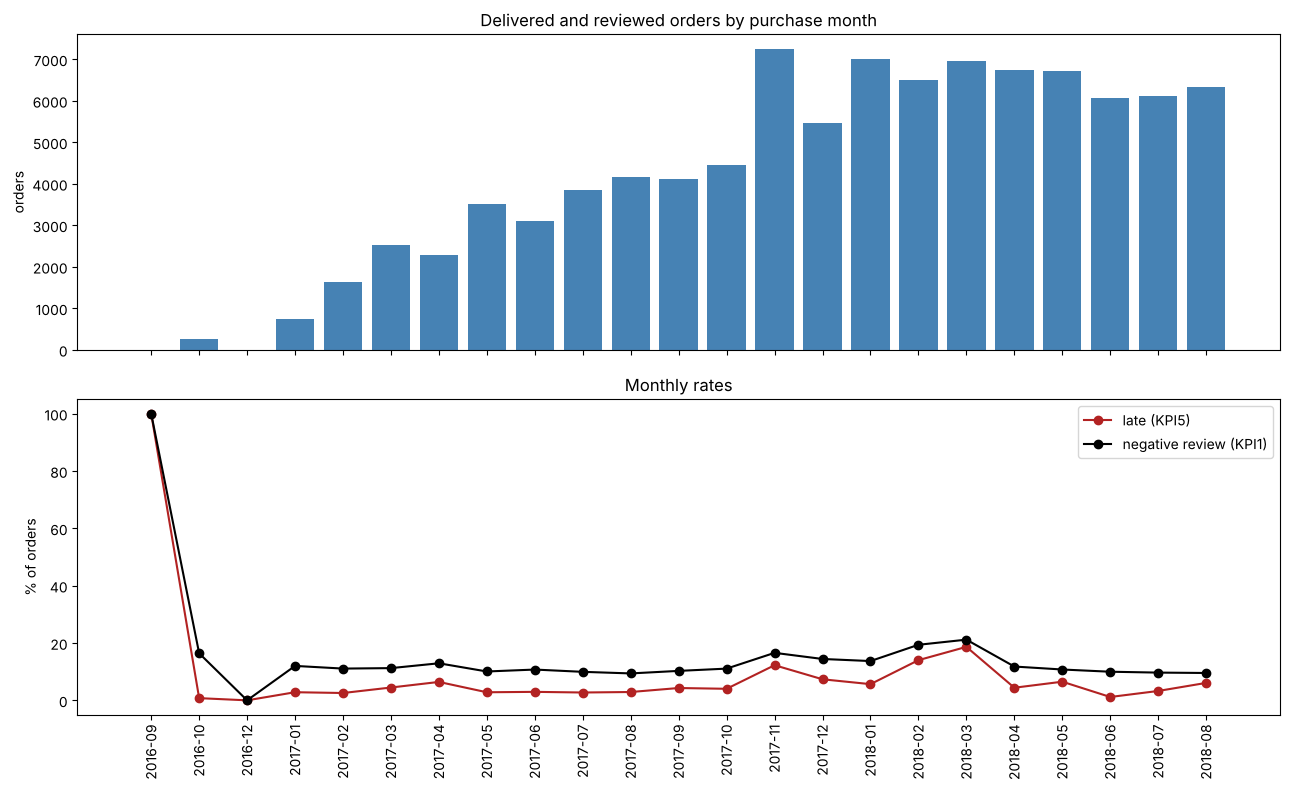

,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa
mes_compra,,,
2016-09,1,100.0,100.0
2016-10,262,0.8,16.4
2016-12,1,0.0,0.0
2017-01,741,2.8,12.0
2017-02,1643,2.6,11.1
2017-03,2527,4.5,11.2
2017-04,2290,6.4,12.9
2017-05,3517,2.8,10.1
2017-06,3111,3.0,10.7


In [12]:
base['mes_compra'] = base['order_purchase_timestamp'].dt.to_period('M')

evolucao_mensal = base.groupby('mes_compra').agg(
    pedidos=('order_id', 'count'),
    taxa_fora_do_prazo=('fora_do_prazo', 'mean'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean')
)

fig, eixos = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
meses = evolucao_mensal.index.astype(str)

eixos[0].bar(meses, evolucao_mensal['pedidos'], color='steelblue')
eixos[0].set_title('Delivered and reviewed orders by purchase month')
eixos[0].set_ylabel('orders')

eixos[1].plot(meses, evolucao_mensal['taxa_fora_do_prazo'] * 100, marker='o', color='firebrick', label='late (KPI5)')
eixos[1].plot(meses, evolucao_mensal['taxa_avaliacao_negativa'] * 100, marker='o', color='black', label='negative review (KPI1)')
eixos[1].set_title('Monthly rates')
eixos[1].set_ylabel('% of orders')
eixos[1].legend()

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

evolucao_mensal.assign(
    taxa_fora_do_prazo=(evolucao_mensal['taxa_fora_do_prazo'] * 100).round(1),
    taxa_avaliacao_negativa=(evolucao_mensal['taxa_avaliacao_negativa'] * 100).round(1)
)

**Reading the results**

**Volume.** The three months of 2016 have residual volume: 1 order in September, 262 in October and 1 in December, with no orders in November. From January 2017, volume grows steadily, passes 4 thousand orders per month in the second half of 2017 and stabilizes between 6 and 7 thousand in 2018. The highest volume of the period is November 2017 (7,237 orders), the month of Black Friday.

**Rates.** The 100% in September 2016 comes from a single order and has no statistical meaning. Through 2017 and 2018, the negative review rate hovers around 10% to 13% in most months, and the late rate is usually between 1% and 7%. There are three moments when both rates rise together:

| Month | Orders | Late | Negative review |
|---|---|---|---|
| 2017-11 | 7,237 | 12.3% | 16.6% |
| 2018-02 | 6,507 | 14.0% | 19.4% |
| 2018-03 | 6,948 | 18.7% | 21.2% |

In March 2018, when the late rate reaches the highest point of the series, the negative review rate also peaks. This joint movement is consistent with H1, but it is still a monthly aggregate association, which will be tested at the order level in section 4.

It is also relevant that, even in months with a low late rate (1% to 3%), the negative review rate does not fall below about 9.5%. In other words, part of the dissatisfaction is not explained by delay, which leaves room for H4 (product complaints).

**Time cutoff decision:** the analysis will consider purchases from **January 2017 to August 2018**. The 2016 months are excluded because their volume is too low to produce stable rates and there is a gap in November 2016, which suggests an initial period of operation or incomplete data collection. The peak months (November 2017, February and March 2018) are kept, because they are part of the real operation and contain precisely the variation in delays that the hypotheses need to observe.

### 3.3 Applying the time cutoff

We apply the cutoff defined in section 3.2, keeping only orders purchased between January 2017 and August 2018. We then recalculate the overall indicators, which become the reference for the comparisons in the following sections.

In [13]:
pedidos_antes_do_recorte = len(base)

base = base[base['mes_compra'] >= pd.Period('2017-01', freq='M')].copy()

print('Orders before the cutoff:', pedidos_antes_do_recorte)
print('Excluded orders (2016):', pedidos_antes_do_recorte - len(base))
print('Orders in the analyzed table:', len(base))
print('Period:', base['mes_compra'].min(), 'to', base['mes_compra'].max())
print()
print(f"Late order rate (KPI5): {base['fora_do_prazo'].mean():.1%}")
print(f"Negative review rate (KPI1): {base['avaliacao_negativa'].mean():.1%}")
print(f"Average score (KPI2): {base['review_score'].mean():.2f}")
print(f"Median delivery time (KPI3): {base['tempo_entrega_dias'].median():.1f} days")
print(f"Median difference from the promised date (KPI4): {base['diferenca_prazo_dias'].median():.0f} days")

Orders before the cutoff: 95824
Excluded orders (2016): 264
Orders in the analyzed table: 95560
Period: 2017-01 to 2018-08

Late order rate (KPI5): 6.7%
Negative review rate (KPI1): 12.8%
Average score (KPI2): 4.16
Median delivery time (KPI3): 10.2 days
Median difference from the promised date (KPI4): -12 days


**Reading the results**

The cutoff removed 264 orders (0.3% of the total), and the analyzed table now has **95,560 orders**, purchased between January 2017 and August 2018. The overall indicators barely changed, which confirms that the 2016 months did not change the overall picture, they only added instability to the monthly series.

Reference values for the following sections:

| Indicator | Value |
|---|---|
| Negative review rate (KPI1) | 12.8% |
| Average score (KPI2) | 4.16 |
| Median delivery time (KPI3) | 10.2 days |
| Median difference from the promised date (KPI4) | 12 days early |
| Late order rate (KPI5) | 6.7% |

### 3.4 Indicators by customer state

For each customer state, we calculate the number of orders, the late order rate, the negative review rate, the average score and the median delivery time. The scatter plot relates each state's late rate and negative review rate, with point size proportional to order volume, since states with few orders produce less stable rates.

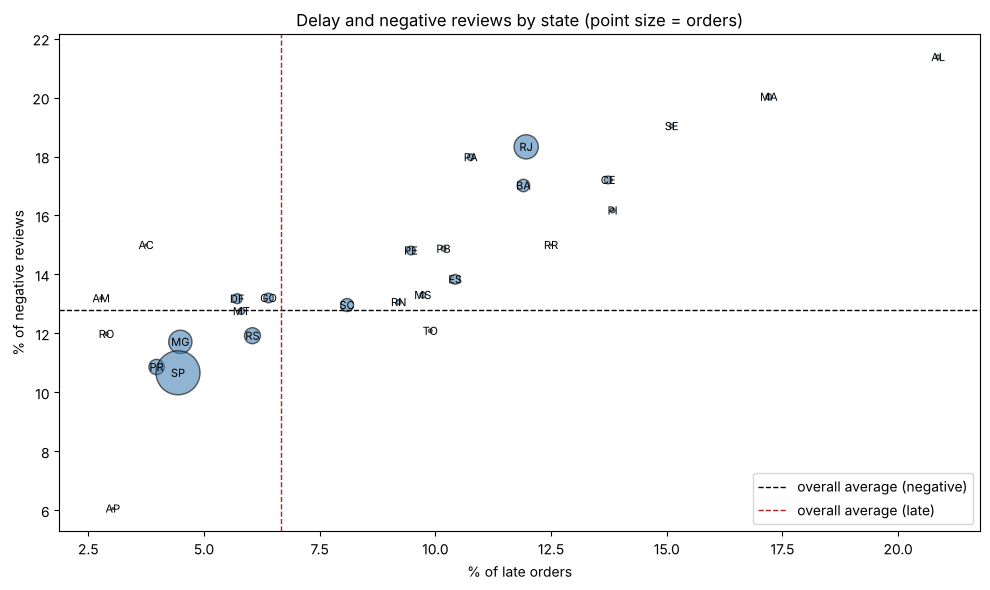

Correlation between the two rates, across states: 0.85


,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa,nota_media,tempo_entrega_mediano
customer_state,,,,,
AL,393,20.9,21.4,3.85,22.3
MA,709,17.2,20.0,3.83,19.1
SE,331,15.1,19.0,3.90,17.9
RJ,12172,12.0,18.3,3.97,12.0
PA,929,10.8,18.0,3.91,21.1
CE,1267,13.7,17.2,3.94,18.2
BA,3226,11.9,17.0,3.93,16.9
PI,470,13.8,16.2,3.99,16.3
AC,80,3.8,15.0,4.09,18.4


In [14]:
por_estado = base.groupby('customer_state').agg(
    pedidos=('order_id', 'count'),
    taxa_fora_do_prazo=('fora_do_prazo', 'mean'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean'),
    nota_media=('review_score', 'mean'),
    tempo_entrega_mediano=('tempo_entrega_dias', 'median')
).sort_values('taxa_avaliacao_negativa', ascending=False)

fig, eixo = plt.subplots(figsize=(10, 6))
eixo.scatter(por_estado['taxa_fora_do_prazo'] * 100, por_estado['taxa_avaliacao_negativa'] * 100,
             s=por_estado['pedidos'] / 40, color='steelblue', alpha=0.6, edgecolor='black')
for estado, linha in por_estado.iterrows():
    eixo.annotate(estado, (linha['taxa_fora_do_prazo'] * 100, linha['taxa_avaliacao_negativa'] * 100),
                  fontsize=8, ha='center', va='center')
eixo.axhline(base['avaliacao_negativa'].mean() * 100, color='black', linestyle='--', linewidth=1, label='overall average (negative)')
eixo.axvline(base['fora_do_prazo'].mean() * 100, color='firebrick', linestyle='--', linewidth=1, label='overall average (late)')
eixo.set_title('Delay and negative reviews by state (point size = orders)')
eixo.set_xlabel('% of late orders')
eixo.set_ylabel('% of negative reviews')
eixo.legend()
plt.tight_layout()
plt.show()

print('Correlation between the two rates, across states:',
      round(por_estado['taxa_fora_do_prazo'].corr(por_estado['taxa_avaliacao_negativa']), 2))

por_estado.assign(
    taxa_fora_do_prazo=(por_estado['taxa_fora_do_prazo'] * 100).round(1),
    taxa_avaliacao_negativa=(por_estado['taxa_avaliacao_negativa'] * 100).round(1),
    nota_media=por_estado['nota_media'].round(2),
    tempo_entrega_mediano=por_estado['tempo_entrega_mediano'].round(1)
)

**Reading the results**

**Relationship between delay and negative reviews.** Across states, the two rates move together strongly (correlation of 0.85). The states with the most delays are also the most dissatisfied: Alagoas (20.9% late; 21.4% negative reviews), Maranhão (17.2%; 20.0%) and Sergipe (15.1%; 19.0%). At the opposite end are São Paulo (4.4%; 10.7%), Paraná (4.0%; 10.9%) and Minas Gerais (4.5%; 11.7%). The Northeast region accounts for most of the states above both averages.

**Rio de Janeiro.** This is the case with the greatest business weight: second largest volume in the table (12,172 orders), 12.0% late and 18.3% negative reviews, almost twice the delay of São Paulo and 7.6 pp more dissatisfaction. The median delivery time in Rio (12.0 days) is not much longer than in Minas Gerais (10.3 days), but the late rate is almost three times higher, which indicates that Rio's problem lies more in meeting the promised date than in the length of the wait.

**Northern states with long waits.** Amazonas, Amapá, Roraima and Acre have the longest median delivery times (between 18 and 26 days), but, except for Roraima, they have low late rates (2.8% to 3.8%) and negative review rates at or below the average (Amapá at 6.1%). Waiting a long time, within a promise that was already long, does not seem to generate the same dissatisfaction as a delay. This pattern is consistent with H1, but the volumes are small (40 to 144 orders), so it only serves as a signal to be tested at the order level.

**Caveats:**

- The 0.85 correlation is calculated across states, giving the same weight to Roraima (40 orders) and São Paulo (40,171 orders). It shows an aggregate pattern, not the order-level relationship, which will be tested in section 4.
- São Paulo accounts for 42% of the table, and São Paulo, Rio de Janeiro and Minas Gerais together account for 66.5%. Since the state relates to both delay and review score, it may act as a confounding factor. For this reason, in section 4, the effect of delay is also checked within São Paulo, the only state with enough volume for a separate test, as a robustness check.

### 3.5 Indicators by product category

We calculate the same indicators by the order's main category. To avoid unstable rates, the comparison only considers categories with at least 500 orders: with this volume and a rate close to 13%, the 95% margin of error is around ±3 pp. Categories with high negative review rates and near-average delays point to dissatisfaction that is not explained by delivery, a relevant signal for H4. Fashion categories (prefix `fashion`) are shown separately, as a complementary cut planned in the decomposition. Category names are kept as they appear in the dataset, in Portuguese.

Categories in the table: 73
Categories with at least 500 orders: 25
Share of these orders in the table: 91.0%
Correlation between the two rates, across comparable categories: 0.64


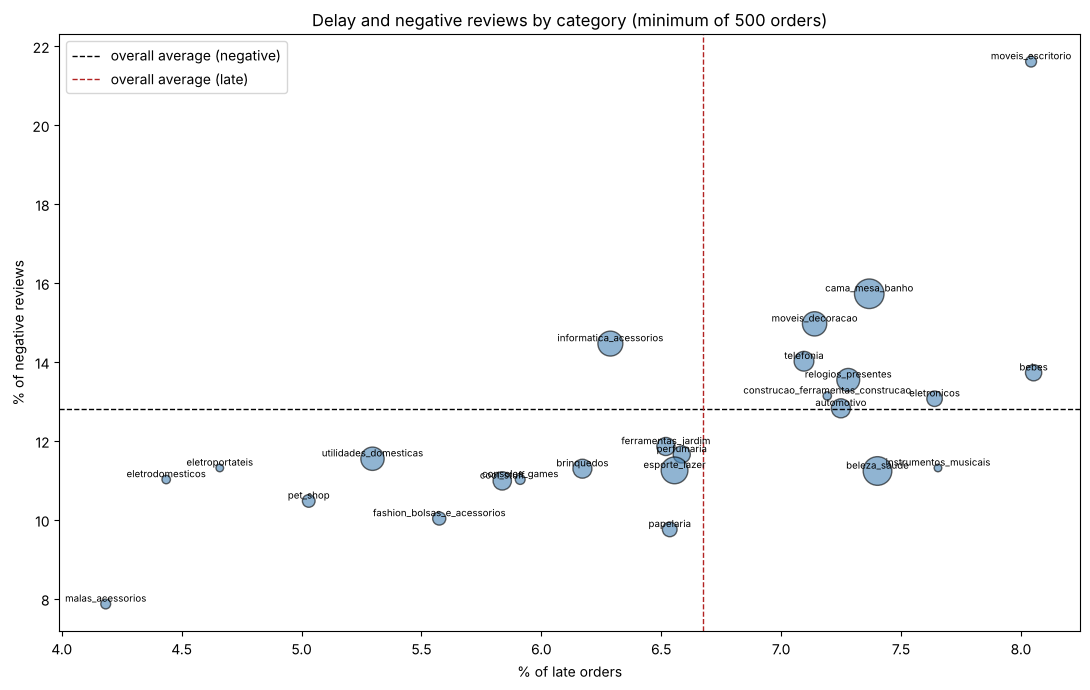


Comparable categories, from highest to lowest negative review rate:


,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa,nota_media,tempo_entrega_mediano
product_category_name,,,,,
moveis_escritorio,1231,8.0,21.6,3.66,18.9
cama_mesa_banho,9067,7.4,15.7,4.01,10.7
moveis_decoracao,6121,7.1,15.0,4.07,10.9
informatica_acessorios,6457,6.3,14.5,4.08,11.1
telefonia,4045,7.1,14.0,4.06,10.8
bebes,2732,8.1,13.7,4.12,10.1
relogios_presentes,5426,7.3,13.5,4.13,10.3
construcao_ferramentas_construcao,723,7.2,13.1,4.13,8.7
eletronicos,2487,7.6,13.1,4.13,11.0



Fashion categories (all, regardless of volume):


,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa,nota_media,tempo_entrega_mediano
product_category_name,,,,,
fashion_roupa_masculina,104,3.8,22.1,3.85,11.1
fashion_roupa_feminina,35,5.7,17.1,3.89,10.8
fashion_underwear_e_moda_praia,116,9.5,16.4,4.01,11.2
fashion_calcados,228,4.4,11.0,4.27,14.2
fashion_bolsas_e_acessorios,1794,5.6,10.0,4.24,9.0
fashion_esporte,24,4.2,4.2,4.54,9.6
fashion_roupa_infanto_juvenil,7,0.0,0.0,5.00,6.4


In [15]:
MINIMO_DE_PEDIDOS = 500

por_categoria = base.groupby('product_category_name').agg(
    pedidos=('order_id', 'count'),
    taxa_fora_do_prazo=('fora_do_prazo', 'mean'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean'),
    nota_media=('review_score', 'mean'),
    tempo_entrega_mediano=('tempo_entrega_dias', 'median')
).sort_values('taxa_avaliacao_negativa', ascending=False)

categorias_comparaveis = por_categoria[por_categoria['pedidos'] >= MINIMO_DE_PEDIDOS]

print('Categories in the table:', len(por_categoria))
print(f'Categories with at least {MINIMO_DE_PEDIDOS} orders:', len(categorias_comparaveis))
print(f"Share of these orders in the table: {categorias_comparaveis['pedidos'].sum() / len(base):.1%}")
print('Correlation between the two rates, across comparable categories:',
      round(categorias_comparaveis['taxa_fora_do_prazo'].corr(categorias_comparaveis['taxa_avaliacao_negativa']), 2))

fig, eixo = plt.subplots(figsize=(11, 7))
eixo.scatter(categorias_comparaveis['taxa_fora_do_prazo'] * 100, categorias_comparaveis['taxa_avaliacao_negativa'] * 100,
             s=categorias_comparaveis['pedidos'] / 20, color='steelblue', alpha=0.6, edgecolor='black')
for categoria, linha in categorias_comparaveis.iterrows():
    eixo.annotate(categoria, (linha['taxa_fora_do_prazo'] * 100, linha['taxa_avaliacao_negativa'] * 100),
                  fontsize=7, ha='center', va='bottom')
eixo.axhline(base['avaliacao_negativa'].mean() * 100, color='black', linestyle='--', linewidth=1, label='overall average (negative)')
eixo.axvline(base['fora_do_prazo'].mean() * 100, color='firebrick', linestyle='--', linewidth=1, label='overall average (late)')
eixo.set_title(f'Delay and negative reviews by category (minimum of {MINIMO_DE_PEDIDOS} orders)')
eixo.set_xlabel('% of late orders')
eixo.set_ylabel('% of negative reviews')
eixo.legend()
plt.tight_layout()
plt.show()

def formatar(tabela):
    return tabela.assign(
        taxa_fora_do_prazo=(tabela['taxa_fora_do_prazo'] * 100).round(1),
        taxa_avaliacao_negativa=(tabela['taxa_avaliacao_negativa'] * 100).round(1),
        nota_media=tabela['nota_media'].round(2),
        tempo_entrega_mediano=tabela['tempo_entrega_mediano'].round(1)
    )

print('\nComparable categories, from highest to lowest negative review rate:')
display(formatar(categorias_comparaveis))

print('\nFashion categories (all, regardless of volume):')
display(formatar(por_categoria[por_categoria.index.str.startswith('fashion')]))

**Reading the results**

The table has 73 categories, but only 25 have at least 500 orders. These 25 account for 91.0% of the table, so the comparison covers almost all of the volume without relying on unstable rates.

**Category varies little in delay and a lot in dissatisfaction.** Among comparable categories, the late rate falls within a narrow range, from 4.2% to 8.1%. The negative review rate, however, ranges from 7.9% to 21.6%. Across states, the late rate ranged from 2.8% to 20.9%. This indicates that delay is explained mainly by geography, not by the type of product. The correlation between the two rates by category (0.64) is positive but weaker than by state (0.85), which leaves room for factors other than delivery.

**Categories where dissatisfaction goes beyond delay:**

| Category | Orders | Late | Negative review |
|---|---|---|---|
| moveis_escritorio (office furniture) | 1,231 | 8.0% | 21.6% |
| cama_mesa_banho (bed, bath and table) | 9,067 | 7.4% | 15.7% |
| moveis_decoracao (furniture and decor) | 6,121 | 7.1% | 15.0% |
| informatica_acessorios (computer accessories) | 6,457 | 6.3% | 14.5% |

`moveis_escritorio` is the most extreme case: its negative review rate is the highest among comparable categories, well above categories with similar delays, such as `bebes` (baby products; 8.1%; 13.7%) and `eletronicos` (electronics; 7.6%; 13.1%). `informatica_acessorios` has a below-average late rate and, even so, an above-average negative review rate. The opposite also happens: `beleza_saude` (health and beauty) has 7.4% late and only 11.2% negative reviews.

These deviations do not prove that the product is the problem, but they show where H4 should look: categories with dissatisfaction that delay does not explain are natural candidates to concentrate complaints about quality, defects or mismatch with the listing.

**Fashion (complementary cut).** Only `fashion_bolsas_e_acessorios` (bags and accessories) has enough volume for comparison (1,794 orders), and it performs better than average (5.6% late; 10.0% negative reviews). The other fashion categories have between 7 and 228 orders. The 22.1% rate in `fashion_roupa_masculina` (menswear), for example, comes from 104 orders, with a margin of error of about ±8 pp.

### 3.6 First look at the relationship between the difference from the promised date and the review

We calculate the average score and the negative review rate for each value of the difference from the promised date, between 40 days early and 30 days late, along with the number of orders on each day. The goal is to see whether the review changes level when the order passes the promised date (H1) and whether the slope of the curve differs between the late side and the early side (H3). The number of orders per day shows how far the averages are stable enough to be included in the tests.

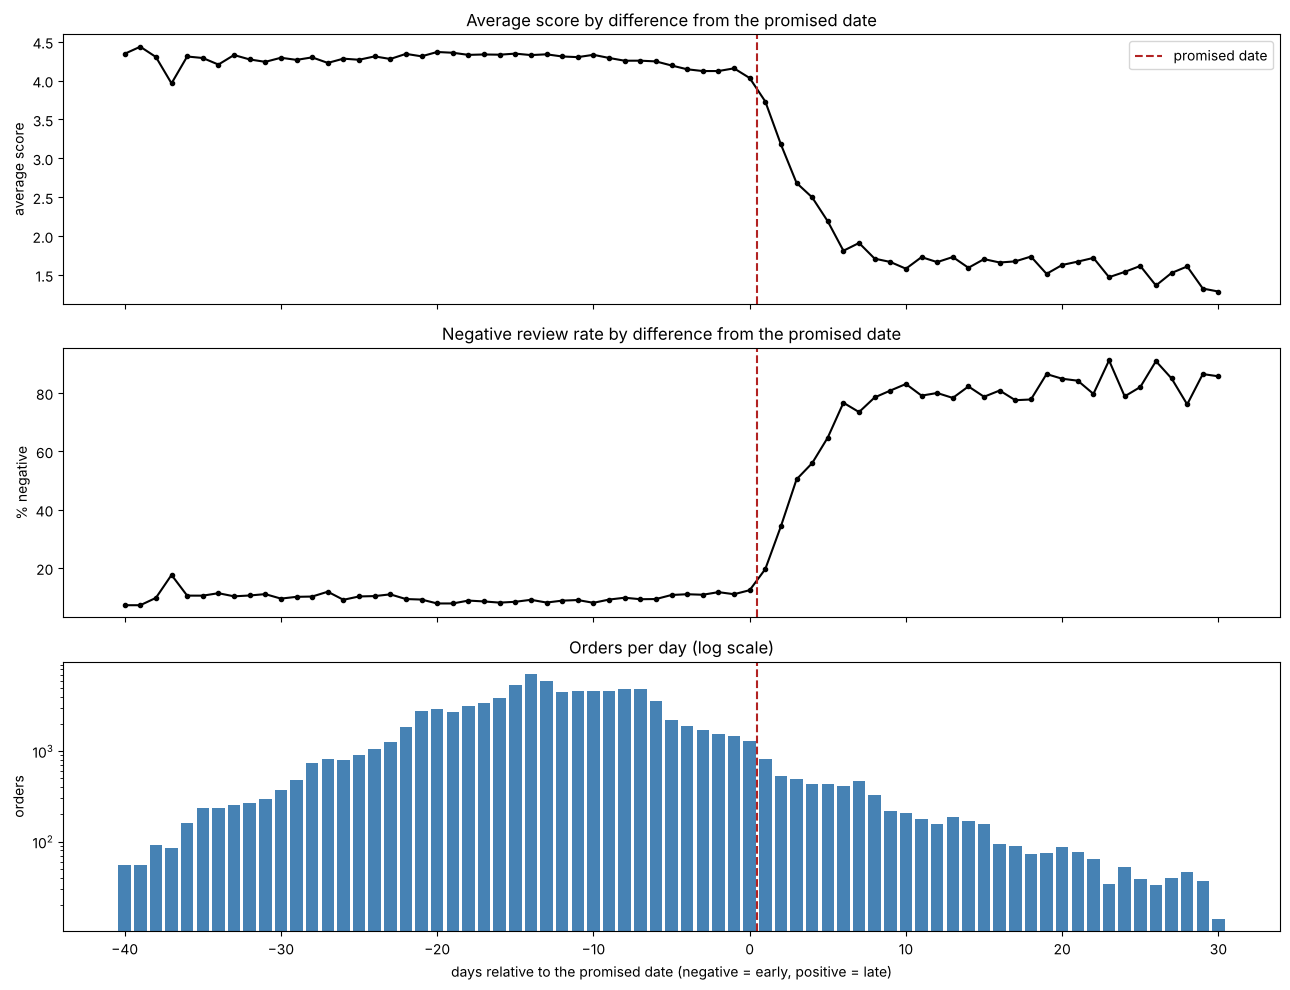

,pedidos,nota_media,taxa_avaliacao_negativa
diferenca_prazo_dias,,,
-30,367,4.29,9.5
-20,2947,4.37,7.9
-15,5317,4.35,8.4
-10,4618,4.33,8.1
-5,2208,4.19,10.8
-3,1713,4.12,10.9
-2,1540,4.12,11.8
-1,1449,4.16,11.0
0,1280,4.03,12.4


In [16]:
JANELA_EXPLORATORIA = (-40, 30)

por_dia = base[base['diferenca_prazo_dias'].between(*JANELA_EXPLORATORIA)].groupby('diferenca_prazo_dias').agg(
    pedidos=('order_id', 'count'),
    nota_media=('review_score', 'mean'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean')
)

fig, eixos = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

eixos[0].plot(por_dia.index, por_dia['nota_media'], marker='o', markersize=3, color='black')
eixos[0].axvline(0.5, color='firebrick', linestyle='--', label='promised date')
eixos[0].set_title('Average score by difference from the promised date')
eixos[0].set_ylabel('average score')
eixos[0].legend()

eixos[1].plot(por_dia.index, por_dia['taxa_avaliacao_negativa'] * 100, marker='o', markersize=3, color='black')
eixos[1].axvline(0.5, color='firebrick', linestyle='--')
eixos[1].set_title('Negative review rate by difference from the promised date')
eixos[1].set_ylabel('% negative')

eixos[2].bar(por_dia.index, por_dia['pedidos'], color='steelblue')
eixos[2].axvline(0.5, color='firebrick', linestyle='--')
eixos[2].set_yscale('log')
eixos[2].set_title('Orders per day (log scale)')
eixos[2].set_ylabel('orders')
eixos[2].set_xlabel('days relative to the promised date (negative = early, positive = late)')

plt.tight_layout()
plt.show()

DIAS_EM_DESTAQUE = [-30, -20, -15, -10, -5, -3, -2, -1, 0, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30]
por_dia.loc[por_dia.index.isin(DIAS_EM_DESTAQUE)].assign(
    nota_media=por_dia['nota_media'].round(2),
    taxa_avaliacao_negativa=(por_dia['taxa_avaliacao_negativa'] * 100).round(1)
)

**Reading the results**

**Early side.** The average score is practically stable between 40 and 5 days early, around 4.3, with a negative review rate between 8% and 11%. Arriving 30 days early (4.29) does not earn a better review than arriving 10 days early (4.33). There is a slight drop as delivery gets closer to the promised date: 4.19 at 5 days early and 4.03 on the promised day itself.

**Late side.** From the first day of delay, the review drops sharply and continuously for about a week:

| Days after the promised date | Average score | Negative review |
|---|---|---|
| 0 (on the day) | 4.03 | 12.4% |
| 1 | 3.73 | 19.7% |
| 3 | 2.68 | 50.4% |
| 5 | 2.19 | 64.7% |
| 7 | 1.91 | 73.5% |
| 10 | 1.58 | 83.1% |

From about 8 to 10 days late, the curve levels off: the score stays around 1.6 and the negative review rate around 80%. More days of delay no longer worsen the review much, because it is already close to the lowest possible value.

**What this suggests for the hypotheses:**

- **H1:** the break happens exactly at the promised date, not over the waiting time. This is consistent with the idea that customers react to the broken promise. The formal test needs to compare orders with similar delivery times, which is done in section 4.1.
- **H2:** the drop after the promised date is not a single step but a ramp over several days. On the first day of delay, the negative review rate (19.7%) is still far from the 80% plateau. One possible explanation, to be tested in section 4.2, is that the share of customers who answer the survey before receiving the order grows as the delay grows.
- **H3:** visually, the slope is almost flat on the early side and very steep on the late side, which is consistent with the asymmetry predicted by loss aversion. Since the late curve levels off after about a week, a line-slope comparison only makes sense in a window close to the promised date. In the first 7 days of delay, each day has more than 400 orders, while from 20 days late there are fewer than 100 orders per day. The H3 window will be defined in section 4.3 based on these two criteria: volume per day and the stretch before the curve levels off.

## 4. Hypothesis testing

Significance level: α = 5%. When a hypothesis involves several simultaneous comparisons, we apply the Bonferroni correction. Besides p-values, we report effect sizes (differences in percentage points and in score points), because in a table with almost 100 thousand orders, small differences tend to be statistically significant without being relevant to the business. Since the data are observational, the results indicate association, not causation.

### 4.1 H1: broken delivery promise versus waiting time

**Hypothesis:** breaking the delivery promise is associated with a larger drop in the review than the waiting time itself.

Late orders also tend to be those that take longest to arrive, so a direct comparison between late and on-time orders would mix the two effects. To separate them, we split orders into delivery time bands and compare late and on-time orders within each band. If the difference persists in every band, delay has an association with the review that is not explained by the length of the wait alone.

In this first step, we show the descriptive figures by band, to check the volume of each group before the tests.

In [17]:
FAIXAS_DE_TEMPO = [0, 7, 14, 21, 30, float('inf')]
ROTULOS_DAS_FAIXAS = ['0 to 7 days', '7 to 14 days', '14 to 21 days', '21 to 30 days', 'over 30 days']

base['faixa_tempo_entrega'] = pd.cut(base['tempo_entrega_dias'], bins=FAIXAS_DE_TEMPO,
                                     labels=ROTULOS_DAS_FAIXAS, right=False)

h1_descritivo = base.groupby(['faixa_tempo_entrega', 'fora_do_prazo'], observed=True).agg(
    pedidos=('order_id', 'count'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean'),
    nota_media=('review_score', 'mean')
).unstack('fora_do_prazo')

h1_descritivo.columns = [f'{indicador} ({"late" if fora else "on time"})'
                         for indicador, fora in h1_descritivo.columns]

h1_descritivo['diferenca_negativa_pp'] = (
    h1_descritivo['taxa_avaliacao_negativa (late)'] - h1_descritivo['taxa_avaliacao_negativa (on time)']
) * 100
h1_descritivo['diferenca_nota'] = (
    h1_descritivo['nota_media (late)'] - h1_descritivo['nota_media (on time)']
)

for coluna in ['taxa_avaliacao_negativa (on time)', 'taxa_avaliacao_negativa (late)']:
    h1_descritivo[coluna] = h1_descritivo[coluna] * 100

h1_descritivo.round(2)

,pedidos (on time),pedidos (late),taxa_avaliacao_negativa (on time),taxa_avaliacao_negativa (late),nota_media (on time),nota_media (late),diferenca_negativa_pp,diferenca_nota
faixa_tempo_entrega,,,,,,,,
0 to 7 days,25866,58,7.44,12.07,4.42,3.98,4.63,-0.44
7 to 14 days,39584,313,8.77,32.59,4.32,3.35,23.82,-0.97
14 to 21 days,16997,526,10.70,43.16,4.18,2.91,32.46,-1.26
21 to 30 days,5823,2009,14.39,53.01,3.96,2.59,38.62,-1.37
over 30 days,912,3472,21.49,74.31,3.67,1.86,52.82,-1.81


**Reading the descriptive results**

In every delivery time band, late orders have a higher negative review rate and a lower average score than on-time orders with a similar wait.

To size the two effects, we compare what happens on each axis:

- **Effect of waiting (no delay):** among on-time orders, the negative review rate rises from 7.4% (up to 7 days) to 21.5% (over 30 days). In other words, waiting more than a month, within the promised date, adds about 14 pp of dissatisfaction.
- **Effect of delay (similar wait):** within the same time band, being late adds from 23.8 pp (7 to 14 days) to 52.8 pp (over 30 days) of negative reviews.

In the 14 to 21 day band, for example, an on-time order has 10.7% negative reviews, while a late order that took practically the same time to arrive has 43.2%. The 32.5 pp difference is larger than the entire effect of waiting observed among on-time orders.

**Two caveats:**

- The 0 to 7 day band has only 58 late orders. The observed difference (4.6 pp) may not be statistically reliable, which will be checked in the test.
- The difference grows in the longer bands partly because they include longer delays: an order that took more than 30 days and is late tends to be more days late than one that took 7 to 14 days. The effect per day of delay is addressed in H3.

**Statistical test by delivery time band**

Hypotheses tested in each band:

- **H₀:** the negative review rate (and the score distribution) is the same for on-time and late orders.
- **H₁:** the negative review rate (and the score distribution) differs between the two groups.

For the negative review rate (KPI1), we use the two-proportion z-test. For the score (KPI2), we use the Mann-Whitney test, which is appropriate because the score is an ordinal variable, concentrated at 5 and not normally distributed. Since there are five simultaneous comparisons, we apply the Bonferroni correction: a band is only considered significant if both tests have a p-value below 0.05 / 5 = 0.01.

In [18]:
ALFA = 0.05
NUMERO_DE_COMPARACOES = len(ROTULOS_DAS_FAIXAS)
ALFA_BONFERRONI = ALFA / NUMERO_DE_COMPARACOES


def teste_z_proporcoes(sucessos_a, total_a, sucessos_b, total_b):
    """Two-sided z-test for the difference between two proportions."""
    p_a = sucessos_a / total_a
    p_b = sucessos_b / total_b
    p_combinada = (sucessos_a + sucessos_b) / (total_a + total_b)
    erro_padrao = math.sqrt(p_combinada * (1 - p_combinada) * (1 / total_a + 1 / total_b))
    z = (p_a - p_b) / erro_padrao
    p_valor = 2 * (1 - st.norm.cdf(abs(z)))
    return z, p_valor


resultados_h1 = []
for faixa in ROTULOS_DAS_FAIXAS:
    grupo = base[base['faixa_tempo_entrega'] == faixa]
    no_prazo = grupo[~grupo['fora_do_prazo']]
    fora_do_prazo = grupo[grupo['fora_do_prazo']]

    z, p_valor_negativa = teste_z_proporcoes(
        fora_do_prazo['avaliacao_negativa'].sum(), len(fora_do_prazo),
        no_prazo['avaliacao_negativa'].sum(), len(no_prazo)
    )
    p_valor_nota = st.mannwhitneyu(
        fora_do_prazo['review_score'], no_prazo['review_score'], alternative='two-sided'
    ).pvalue

    resultados_h1.append({
        'band': faixa,
        'late orders': len(fora_do_prazo),
        'difference in negative rate (pp)': round((fora_do_prazo['avaliacao_negativa'].mean()
                                                  - no_prazo['avaliacao_negativa'].mean()) * 100, 1),
        'p-value (z-test)': p_valor_negativa,
        'difference in score': round(fora_do_prazo['review_score'].mean() - no_prazo['review_score'].mean(), 2),
        'p-value (Mann-Whitney)': p_valor_nota,
        'significant after Bonferroni': (p_valor_negativa < ALFA_BONFERRONI) and (p_valor_nota < ALFA_BONFERRONI)
    })

print(f'Bonferroni-adjusted alpha: {ALFA_BONFERRONI:.3f}')
pd.DataFrame(resultados_h1).set_index('band')

Bonferroni-adjusted alpha: 0.010


,late orders,difference in negative rate (pp),p-value (z-test),difference in score,p-value (Mann-Whitney),significant after Bonferroni
band,,,,,,
0 to 7 days,58,4.6,0.179712,-0.44,1.250413e-03,False
7 to 14 days,313,23.8,0.000000,-0.97,1.567407e-33,True
14 to 21 days,526,32.5,0.000000,-1.26,5.245312e-79,True
21 to 30 days,2009,38.6,0.000000,-1.37,4.212635e-218,True
over 30 days,3472,52.8,0.000000,-1.81,2.011668e-204,True


**Reading the results**

P-values shown as 0.000000 are smaller than the numerical precision of the calculation (below 10⁻¹⁶), that is, practically zero.

- **Bands of 7 to 14, 14 to 21, 21 to 30 and over 30 days:** we reject H₀ in both tests, well below the adjusted α of 0.01. Within each band, late orders have 23.8 to 52.8 pp more negative reviews and 0.97 to 1.81 points lower average scores.
- **0 to 7 day band:** the difference in the negative review rate (4.6 pp) is not significant (p = 0.18). The difference in score (−0.44) passes the Mann-Whitney test (p = 0.001), but under the adopted criterion, which requires both tests, the band is not considered significant. With only 58 late orders, the test has little power to detect differences in this band.

The four significant bands contain 6,320 of the 6,378 late orders in the table (99.1%).

**Conclusion on H1:** the data support the hypothesis. With a similar waiting time, being late is associated with a sharp drop in the review, larger than the effect of waiting longer within the promised date (about 14 pp between the shortest and longest bands, as seen in the descriptive analysis). This result is consistent with the expectation disconfirmation model (Oliver, 1980): what weighs on the review is the gap between what was promised and what was delivered, more than the absolute waiting time.

**Robustness check: does the effect hold within São Paulo?**

Since the customer's state is associated with both delay and review (section 3.4), it may act as a confounding factor. To check whether the H1 result depends on differences between states, we repeat the same test by delivery time band using only orders from São Paulo, the only state with enough volume for this separate analysis. The criteria are the same: z-test for the negative review rate, Mann-Whitney for the score and a Bonferroni-adjusted α of 0.01.

In [19]:
def comparar_atraso_por_faixa(dados):
    """Compares on-time and late orders within each delivery time band."""
    resultados = []
    for faixa in ROTULOS_DAS_FAIXAS:
        grupo = dados[dados['faixa_tempo_entrega'] == faixa]
        no_prazo = grupo[~grupo['fora_do_prazo']]
        fora_do_prazo = grupo[grupo['fora_do_prazo']]

        z, p_valor_negativa = teste_z_proporcoes(
            fora_do_prazo['avaliacao_negativa'].sum(), len(fora_do_prazo),
            no_prazo['avaliacao_negativa'].sum(), len(no_prazo)
        )
        p_valor_nota = st.mannwhitneyu(
            fora_do_prazo['review_score'], no_prazo['review_score'], alternative='two-sided'
        ).pvalue

        resultados.append({
            'band': faixa,
            'on-time orders': len(no_prazo),
            'late orders': len(fora_do_prazo),
            'negative rate on time (%)': round(no_prazo['avaliacao_negativa'].mean() * 100, 1),
            'negative rate late (%)': round(fora_do_prazo['avaliacao_negativa'].mean() * 100, 1),
            'difference in negative rate (pp)': round((fora_do_prazo['avaliacao_negativa'].mean()
                                                      - no_prazo['avaliacao_negativa'].mean()) * 100, 1),
            'p-value (z-test)': p_valor_negativa,
            'difference in score': round(fora_do_prazo['review_score'].mean() - no_prazo['review_score'].mean(), 2),
            'p-value (Mann-Whitney)': p_valor_nota,
            'significant after Bonferroni': (p_valor_negativa < ALFA_BONFERRONI) and (p_valor_nota < ALFA_BONFERRONI)
        })
    return pd.DataFrame(resultados).set_index('band')


pedidos_sp = base[base['customer_state'] == 'SP']
print('Orders from São Paulo:', len(pedidos_sp))
print('Late orders from São Paulo:', pedidos_sp['fora_do_prazo'].sum())
comparar_atraso_por_faixa(pedidos_sp)

Orders from São Paulo: 40171
Late orders from São Paulo: 1783


,on-time orders,late orders,negative rate on time (%),negative rate late (%),difference in negative rate (pp),p-value (z-test),difference in score,p-value (Mann-Whitney),significant after Bonferroni
band,,,,,,,,,
0 to 7 days,18823,52,7.3,11.5,4.2,2.469691e-01,-0.45,1.237161e-03,False
7 to 14 days,15533,281,9.1,31.3,22.3,0.000000e+00,-0.91,2.175581e-27,True
14 to 21 days,3430,379,12.0,47.0,35.0,0.000000e+00,-1.30,9.815639e-53,True
21 to 30 days,532,650,17.3,60.2,42.9,0.000000e+00,-1.47,1.690690e-50,True
over 30 days,70,421,34.3,72.7,38.4,2.345037e-10,-1.38,2.630170e-11,True


**Reading the results**

Within São Paulo (40,171 orders, 1,783 late), the pattern repeats. In the four bands from 7 days up, the difference is significant in both tests, with a magnitude similar to the full table: 22.3 to 42.9 pp more negative reviews among late orders. In the 0 to 7 day band, as in the full table, the difference in the negative review rate is not significant (52 late orders).

Since the effect appears with the same intensity within a single state, it is not explained by the regional differences seen in section 3.4. The H1 result holds.

**H1 summary:** with a similar waiting time, late orders have a negative review rate 22 to 53 pp higher than on-time orders, in every band with enough volume for testing (99.1% of delays). The effect holds within São Paulo. Breaking the promise is associated with a larger drop in the review than the waiting time itself.

### 4.2 H2: review answered before delivery

**Hypothesis:** among late orders, reviews answered before delivery are worse than reviews answered after delivery.

According to the dataset description on Kaggle, the satisfaction survey is sent to the customer on the estimated delivery date. For a late order, the customer may therefore receive the survey before the product and review a purchase they have not yet received. The variable `avaliacao_antes_da_entrega` (reviewed before delivery), created in section 2.7, identifies these cases.

Since the share of answers before delivery tends to grow with the size of the delay, the comparison is made within bands of days late. This way, the observed difference can be attributed to the timing of the answer, not to longer delays. The bands follow the shape of the curve in section 3.6: 1 to 3 days and 4 to 7 days (steep drop), 8 to 14 days and over 14 days (plateau).

In [20]:
pedidos_atrasados = base[base['fora_do_prazo']].copy()

FAIXAS_DE_ATRASO = [0, 3, 7, 14, float('inf')]
ROTULOS_DE_ATRASO = ['1 to 3 days', '4 to 7 days', '8 to 14 days', 'over 14 days']
pedidos_atrasados['faixa_atraso'] = pd.cut(pedidos_atrasados['diferenca_prazo_dias'],
                                           bins=FAIXAS_DE_ATRASO, labels=ROTULOS_DE_ATRASO)

print('Late orders:', len(pedidos_atrasados))
print(f"Answered before delivery: {pedidos_atrasados['avaliacao_antes_da_entrega'].sum()} "
      f"({pedidos_atrasados['avaliacao_antes_da_entrega'].mean():.1%})")
print('On-time orders answered before delivery:',
      base.loc[~base['fora_do_prazo'], 'avaliacao_antes_da_entrega'].sum())

print('\nOverview of late orders:')
display(pedidos_atrasados.groupby('avaliacao_antes_da_entrega').agg(
    pedidos=('order_id', 'count'),
    taxa_avaliacao_negativa=('avaliacao_negativa', lambda x: round(x.mean() * 100, 1)),
    nota_media=('review_score', lambda x: round(x.mean(), 2))
))

print('\nBy delay band:')
h2_descritivo = pedidos_atrasados.groupby(['faixa_atraso', 'avaliacao_antes_da_entrega'], observed=True).agg(
    pedidos=('order_id', 'count'),
    taxa_avaliacao_negativa=('avaliacao_negativa', 'mean'),
    nota_media=('review_score', 'mean')
).unstack('avaliacao_antes_da_entrega')

h2_descritivo.columns = [f'{indicador} ({"before delivery" if antes else "after delivery"})'
                         for indicador, antes in h2_descritivo.columns]
h2_descritivo['% answered before delivery'] = (
    h2_descritivo['pedidos (before delivery)']
    / (h2_descritivo['pedidos (before delivery)'] + h2_descritivo['pedidos (after delivery)']) * 100
)
for coluna in ['taxa_avaliacao_negativa (before delivery)', 'taxa_avaliacao_negativa (after delivery)']:
    h2_descritivo[coluna] = h2_descritivo[coluna] * 100

h2_descritivo.round(2)

Late orders: 6378
Answered before delivery: 4471 (70.1%)
On-time orders answered before delivery: 177

Overview of late orders:


,pedidos,taxa_avaliacao_negativa,nota_media
avaliacao_antes_da_entrega,,,
False,1907,19.5,3.72
True,4471,80.7,1.65



By delay band:


,pedidos (after delivery),pedidos (before delivery),taxa_avaliacao_negativa (after delivery),taxa_avaliacao_negativa (before delivery),nota_media (after delivery),nota_media (before delivery),% answered before delivery
faixa_atraso,,,,,,,
1 to 3 days,1435,416,18.61,78.85,3.75,1.72,22.47
4 to 7 days,396,1352,20.45,81.51,3.69,1.64,77.35
8 to 14 days,57,1389,26.32,82.36,3.53,1.59,96.06
over 14 days,19,1314,42.11,78.84,2.89,1.71,98.57


**Reading the descriptive results**

Of the 6,378 late orders, 4,471 (70.1%) had the survey answered before delivery. Among on-time orders, this happened in only 177 cases, which confirms that answering before receiving the product is, in practice, a late-order phenomenon.

**The difference is large and stable in every delay band.** Among late orders, those who answered before delivery have about 80% negative reviews, while those who answered after have between 19% and 42%:

| Delay band | Negative (after delivery) | Negative (before delivery) | % answered before |
|---|---|---|---|
| 1 to 3 days | 18.6% | 78.9% | 22.5% |
| 4 to 7 days | 20.4% | 81.5% | 77.4% |
| 8 to 14 days | 26.3% | 82.4% | 96.1% |
| over 14 days | 42.1% | 78.8% | 98.6% |

Two patterns stand out:

- **Within each band, the timing of the answer weighs more than the size of the delay.** The negative review rate of those who answered before delivery is practically constant (79% to 82%), whether the delay is 2 days or 3 weeks.
- **The share of answers before delivery follows the ramp in section 3.6.** It rises from 22.5% for delays of 1 to 3 days to 77.4% for 4 to 7 days and exceeds 96% from 8 days on. This offers an explanation for the shape of the curve: the average review of late orders worsens over the first week because, with each day of delay, a larger share of customers answers the survey without having received the product. Once almost everyone answers before, the curve levels off.

**Caveats:** the bands above 7 days have few orders answered after delivery (57 and 19), so that group's rates are unstable. In addition, the timing of the answer is the customer's choice: more dissatisfied customers may answer faster. For this reason, the result indicates an association between answering before delivery and reviewing worse, and does not prove that the timing of the survey causes the negative review.

**Statistical test by delay band**

Hypotheses tested in each delay band:

- **H₀:** among late orders, the negative review rate (and the score distribution) is the same for reviews answered before and after delivery.
- **H₁:** the negative review rate (and the score distribution) differs between the two groups.

We use the same tests as in section 4.1 (two-proportion z-test and Mann-Whitney). With four bands, the Bonferroni-adjusted α is 0.05 / 4 = 0.0125, and a band is considered significant only if both tests fall below this value.

In [21]:
ALFA_BONFERRONI_H2 = ALFA / len(ROTULOS_DE_ATRASO)

resultados_h2 = []
for faixa in ROTULOS_DE_ATRASO:
    grupo = pedidos_atrasados[pedidos_atrasados['faixa_atraso'] == faixa]
    antes = grupo[grupo['avaliacao_antes_da_entrega']]
    depois = grupo[~grupo['avaliacao_antes_da_entrega']]

    z, p_valor_negativa = teste_z_proporcoes(
        antes['avaliacao_negativa'].sum(), len(antes),
        depois['avaliacao_negativa'].sum(), len(depois)
    )
    p_valor_nota = st.mannwhitneyu(
        antes['review_score'], depois['review_score'], alternative='two-sided'
    ).pvalue

    resultados_h2.append({
        'delay band': faixa,
        'answered before': len(antes),
        'answered after': len(depois),
        'difference in negative rate (pp)': round((antes['avaliacao_negativa'].mean()
                                                  - depois['avaliacao_negativa'].mean()) * 100, 1),
        'p-value (z-test)': p_valor_negativa,
        'difference in score': round(antes['review_score'].mean() - depois['review_score'].mean(), 2),
        'p-value (Mann-Whitney)': p_valor_nota,
        'significant after Bonferroni': (p_valor_negativa < ALFA_BONFERRONI_H2) and (p_valor_nota < ALFA_BONFERRONI_H2)
    })

print(f'Bonferroni-adjusted alpha: {ALFA_BONFERRONI_H2:.4f}')
pd.DataFrame(resultados_h2).set_index('delay band')

Bonferroni-adjusted alpha: 0.0125


,answered before,answered after,difference in negative rate (pp),p-value (z-test),difference in score,p-value (Mann-Whitney),significant after Bonferroni
delay band,,,,,,,
1 to 3 days,416,1435,60.2,0.000000,-2.02,8.706412e-104,True
4 to 7 days,1352,396,61.1,0.000000,-2.05,1.735985e-117,True
8 to 14 days,1389,57,56.0,0.000000,-1.93,3.014637e-22,True
over 14 days,1314,19,36.7,0.000114,-1.19,1.006521e-04,True


**Reading the results**

We reject H₀ in all four delay bands, in both tests, with p-values below the adjusted α of 0.0125. Among late orders, answering the survey before delivery is associated with:

- **56 to 61 pp more negative reviews** and about **2 points lower average score** in the bands from 1 to 14 days late, which contain the vast majority of cases;
- 36.7 pp more negative reviews and 1.19 points lower score in the band over 14 days. This smaller effect should be read with caution, because the group that answered after delivery has only 19 orders.

**Conclusion on H2:** the data support the hypothesis. Among late orders, customers who answer the survey before receiving the product review much worse than those who answer after, and this holds in every delay band, meaning it is not explained by the size of the delay. Combined with the pattern in section 3.6, the result suggests that much of the drop associated with delay is concentrated in reviews made before delivery. Since these are observational data in which the customer chooses when to answer, a causal link between sending the survey on the estimated date and the negative review cannot be established from this dataset. It is a natural candidate for an A/B test, proposed in the recommendations.

### 4.3 H3: asymmetry between delay and early delivery

**Hypothesis:** each day of delay lowers the review more than each day of early delivery raises it, in line with loss aversion (Kahneman and Tversky, 1979).

We fit two simple linear regressions of the score on the difference from the promised date: one on the early side (from 7 days early to the promised day) and one on the late side (from 1 to 7 days late). The slope of each line shows the average change in score per day. The lines are fitted on individual orders, so each day weighs according to its volume.

The 7-day window was defined in section 3.6: every day in this range has more than 400 orders, and it comes before the stretch where the late curve levels off. To check whether the conclusion depends on this choice, we repeat the analysis with 5- and 10-day windows.

- **H₀:** the change in score per day is the same, in absolute value, on both sides of the promised date.
- **H₁:** the change in score per day of delay is larger, in absolute value, than the change per day of early delivery.

The comparison uses a one-sided z-test for the difference between the absolute slopes, with α = 5%.

Average score (KPI2):


,early orders,late orders,early slope,95% CI early,late slope,95% CI late,ratio of absolute slopes,z,p-value
window (days),,,,,,,,,
5,10093,2721,-0.0215,"(-0.0355, -0.0075)",-0.3904,"(-0.4306, -0.3502)",18.1,17.0,0.0
7,18509,3599,-0.0275,"(-0.035, -0.02)",-0.3217,"(-0.3454, -0.2981)",11.7,23.2,0.0
10,32530,4355,-0.0253,"(-0.0297, -0.0208)",-0.2565,"(-0.2723, -0.2406)",10.2,27.5,0.0


Negative review rate (KPI1):


,early orders,late orders,early slope,95% CI early,late slope,95% CI late,ratio of absolute slopes,z,p-value
window (days),,,,,,,,,
5,10093,2721,0.0025,"(-0.0012, 0.0061)",0.1153,"(0.1033, 0.1274)",46.9,17.6,0.0
7,18509,3599,0.0041,"(0.0022, 0.0061)",0.0960,"(0.0888, 0.1031)",23.2,24.3,0.0
10,32530,4355,0.0036,"(0.0025, 0.0047)",0.0762,"(0.0714, 0.0811)",21.2,28.6,0.0


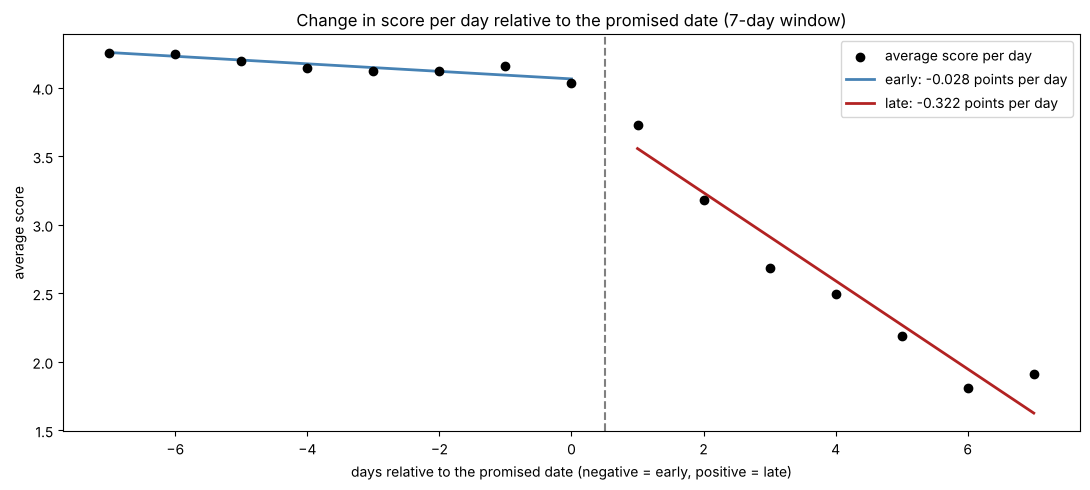

In [22]:
def comparar_inclinacoes(dados, janela, coluna='review_score'):
    """Fits a line on each side of the promised date and tests whether the late slope is larger in absolute value."""
    antecipacao = dados[dados['diferenca_prazo_dias'].between(-janela, 0)]
    atraso = dados[dados['diferenca_prazo_dias'].between(1, janela)]

    reta_antecipacao = st.linregress(antecipacao['diferenca_prazo_dias'], antecipacao[coluna].astype(float))
    reta_atraso = st.linregress(atraso['diferenca_prazo_dias'], atraso[coluna].astype(float))

    z = (abs(reta_atraso.slope) - abs(reta_antecipacao.slope)) / math.sqrt(
        reta_antecipacao.stderr ** 2 + reta_atraso.stderr ** 2)
    p_valor = 1 - st.norm.cdf(z)

    return {
        'window (days)': janela,
        'early orders': len(antecipacao),
        'late orders': len(atraso),
        'early slope': round(reta_antecipacao.slope, 4),
        '95% CI early': (round(reta_antecipacao.slope - 1.96 * reta_antecipacao.stderr, 4),
                               round(reta_antecipacao.slope + 1.96 * reta_antecipacao.stderr, 4)),
        'late slope': round(reta_atraso.slope, 4),
        '95% CI late': (round(reta_atraso.slope - 1.96 * reta_atraso.stderr, 4),
                          round(reta_atraso.slope + 1.96 * reta_atraso.stderr, 4)),
        'ratio of absolute slopes': round(abs(reta_atraso.slope) / abs(reta_antecipacao.slope), 1),
        'z': round(z, 1),
        'p-value': p_valor
    }, reta_antecipacao, reta_atraso


JANELA_H3 = 7

print('Average score (KPI2):')
display(pd.DataFrame([comparar_inclinacoes(base, janela)[0] for janela in [5, JANELA_H3, 10]]).set_index('window (days)'))

print('Negative review rate (KPI1):')
display(pd.DataFrame([comparar_inclinacoes(base, janela, 'avaliacao_negativa')[0] for janela in [5, JANELA_H3, 10]]).set_index('window (days)'))

# Chart for the main window: daily averages and fitted lines
_, reta_antecipacao, reta_atraso = comparar_inclinacoes(base, JANELA_H3)
medias_por_dia = base[base['diferenca_prazo_dias'].between(-JANELA_H3, JANELA_H3)].groupby('diferenca_prazo_dias')['review_score'].mean()

dias_antecipacao = pd.Series(range(-JANELA_H3, 1))
dias_atraso = pd.Series(range(1, JANELA_H3 + 1))

fig, eixo = plt.subplots(figsize=(11, 5))
eixo.scatter(medias_por_dia.index, medias_por_dia.values, color='black', zorder=3, label='average score per day')
eixo.plot(dias_antecipacao, reta_antecipacao.intercept + reta_antecipacao.slope * dias_antecipacao,
          color='steelblue', linewidth=2, label=f'early: {reta_antecipacao.slope:+.3f} points per day')
eixo.plot(dias_atraso, reta_atraso.intercept + reta_atraso.slope * dias_atraso,
          color='firebrick', linewidth=2, label=f'late: {reta_atraso.slope:+.3f} points per day')
eixo.axvline(0.5, color='gray', linestyle='--')
eixo.set_title(f'Change in score per day relative to the promised date ({JANELA_H3}-day window)')
eixo.set_xlabel('days relative to the promised date (negative = early, positive = late)')
eixo.set_ylabel('average score')
eixo.legend()
plt.tight_layout()
plt.show()

**Reading the results**

P-values shown as 0.0 are smaller than the precision of the calculation, that is, practically zero.

**In the full table, the asymmetry is strong and does not depend on the chosen window.** In the main 7-day window:

- each day early is associated with a gain of **0.028 points** in the score (95% CI: 0.020 to 0.035);
- each day late is associated with a loss of **0.322 points** (95% CI: 0.298 to 0.345).

The loss per day of delay is about **12 times** the gain per day early, and the confidence intervals do not overlap. In the negative review rate, each day of delay adds 9.6 pp, against 0.4 pp per day early. With 5- and 10-day windows, the ratio ranges from 10 to 47 times, always with a practically zero p-value. In the 5-day window, the effect of early delivery on the negative review rate is not even significant (the CI includes zero).

**Why this result is not yet enough to confirm H3.** Loss aversion predicts that losses weigh more than equivalent gains, but the magnitude estimated in the literature is much smaller: in Tversky and Kahneman (1992), the loss aversion coefficient is about 2.25. A ratio of 12 suggests that something beyond the psychological reaction to delay is inflating the slope. H2 points to the candidate: in section 4.2, we saw that the share of answers before delivery rises from 22% to 77% precisely over the first week of delay, and that those who answer before review much worse. If so, the slope on the late side largely measures the change in who is answering, not the effect of each day of delay on the review. This possibility is checked next.

**Robustness check: asymmetry among customers who reviewed after delivery**

The H2 results show that the share of reviews answered before delivery grows over the first week of delay, and that these reviews are much more negative. This may inflate the estimated slope on the late side. To isolate the change in score associated with each day of delay, we repeat the slope comparison using only reviews answered after delivery, where the customer reviews with the product in hand and knows the total delay.

In this subset, the late side has fewer orders, especially in the last days of the window. The volume per day is shown alongside, so the precision of the estimates can be assessed.

In [23]:
avaliados_depois_da_entrega = base[~base['avaliacao_antes_da_entrega']]

print('Orders with the review answered after delivery:', len(avaliados_depois_da_entrega))

print('\nAverage score (KPI2):')
display(pd.DataFrame([comparar_inclinacoes(avaliados_depois_da_entrega, janela)[0]
                      for janela in [5, JANELA_H3, 10]]).set_index('window (days)'))

print('Negative review rate (KPI1):')
display(pd.DataFrame([comparar_inclinacoes(avaliados_depois_da_entrega, janela, 'avaliacao_negativa')[0]
                      for janela in [5, JANELA_H3, 10]]).set_index('window (days)'))

print('Volume and average score per day of delay, among those who reviewed after delivery:')
avaliados_depois_da_entrega[avaliados_depois_da_entrega['diferenca_prazo_dias'].between(1, 10)].groupby(
    'diferenca_prazo_dias').agg(
    pedidos=('order_id', 'count'),
    nota_media=('review_score', lambda x: round(x.mean(), 2)),
    taxa_avaliacao_negativa=('avaliacao_negativa', lambda x: round(x.mean() * 100, 1))
)

Orders with the review answered after delivery: 90912

Average score (KPI2):


,early orders,late orders,early slope,95% CI early,late slope,95% CI late,ratio of absolute slopes,z,p-value
window (days),,,,,,,,,
5,10059,1722,-0.0208,"(-0.0348, -0.0068)",-0.0201,"(-0.0713, 0.0312)",1.0,-0.0,0.510396
7,18460,1831,-0.0271,"(-0.0346, -0.0196)",-0.0240,"(-0.0634, 0.0153)",0.9,-0.2,0.559991
10,32441,1871,-0.0251,"(-0.0296, -0.0207)",-0.0170,"(-0.051, 0.0169)",0.7,-0.5,0.678015


Negative review rate (KPI1):


,early orders,late orders,early slope,95% CI early,late slope,95% CI late,ratio of absolute slopes,z,p-value
window (days),,,,,,,,,
5,10059,1722,0.0023,"(-0.0013, 0.0059)",0.0060,"(-0.0086, 0.0205)",2.6,0.5,0.316821
7,18460,1831,0.0040,"(0.0021, 0.0059)",0.0057,"(-0.0055, 0.0169)",1.4,0.3,0.384896
10,32441,1871,0.0035,"(0.0024, 0.0047)",0.0037,"(-0.0059, 0.0133)",1.1,0.0,0.484167


Volume and average score per day of delay, among those who reviewed after delivery:


,pedidos,nota_media,taxa_avaliacao_negativa
diferenca_prazo_dias,,,
1,798,3.78,18.3
2,383,3.70,18.3
3,254,3.71,20.1
4,171,3.80,18.7
5,116,3.63,21.6
6,60,3.40,28.3
7,49,3.82,14.3
8,18,3.39,16.7
9,13,4.08,15.4


**Reading the results**

Among the 90,912 orders reviewed after delivery, **the per-day asymmetry disappears**. In the main 7-day window:

- each day early is associated with a gain of 0.027 points in the score (95% CI: 0.020 to 0.035);
- each day late is associated with a loss of 0.024 points (95% CI: from a 0.063 loss to a 0.015 gain), an estimate that cannot be distinguished from zero.

The ratio between the slopes drops from 11.7 to 0.9, and we do not reject H₀ in any of the three windows, either for the score or for the negative review rate (p-values between 0.32 and 0.68). The per-day table shows the same: among those who reviewed with the product in hand, the score stays around 3.7 to 3.8 and the negative review rate around 18% to 20% from the first to the fifth day of delay, without the progressive drop seen in the full table.

**What this means:** the steep slope observed in the full table is largely explained by the change in who is answering. Over the first week of delay, the share of customers who review before receiving the product grows (H2), and those reviews pull the average down. Among those who review after delivery, one more day of delay is not associated with a detectable additional drop.

**Limitations of this check:**

- The late side has only 1,831 orders in this subset, and volume falls below 100 per day from the sixth day of delay. For this reason, the confidence interval of the late slope is wide. It rules out the 12-fold asymmetry of the full table, but does not rule out a moderate asymmetry, of the order of the 2.25 coefficient estimated by Tversky and Kahneman (1992). The correct conclusion is that **the data cannot detect** a per-day asymmetry, not that it does not exist.
- Late customers who wait for the product to arrive before answering may be, on average, less dissatisfied than those who answer before. This possible selection bias cannot be controlled with the available data.

If the drop does not grow day by day among those who review with the product in hand, it remains to check whether it happens **all at once**, when the promised date is passed. That is what we test next.

**The step at the promised date**

To check whether the drop associated with delay happens when the promised date is passed, we compare two groups close to the limit, both among reviews answered after delivery: orders delivered between 3 days early and the promised day, and orders delivered 1 to 3 days late. Since they are only a few days apart, the two groups have similar waiting times, and the difference between them approximates the effect of crossing the promised limit.

- **H₀:** the negative review rate (and the score distribution) is the same in both groups.
- **H₁:** the negative review rate (and the score distribution) differs between the two groups.

We use the two-proportion z-test and the Mann-Whitney test, with α = 5%.

In [24]:
DIAS_PROXIMOS_AO_PRAZO = 3

ultimos_dias_no_prazo = avaliados_depois_da_entrega[
    avaliados_depois_da_entrega['diferenca_prazo_dias'].between(-DIAS_PROXIMOS_AO_PRAZO, 0)]
primeiros_dias_de_atraso = avaliados_depois_da_entrega[
    avaliados_depois_da_entrega['diferenca_prazo_dias'].between(1, DIAS_PROXIMOS_AO_PRAZO)]

z, p_valor_negativa = teste_z_proporcoes(
    primeiros_dias_de_atraso['avaliacao_negativa'].sum(), len(primeiros_dias_de_atraso),
    ultimos_dias_no_prazo['avaliacao_negativa'].sum(), len(ultimos_dias_no_prazo)
)
p_valor_nota = st.mannwhitneyu(
    primeiros_dias_de_atraso['review_score'], ultimos_dias_no_prazo['review_score'], alternative='two-sided'
).pvalue

pd.DataFrame({
    'orders': [len(ultimos_dias_no_prazo), len(primeiros_dias_de_atraso)],
    'median delivery time (days)': [round(ultimos_dias_no_prazo['tempo_entrega_dias'].median(), 1),
                                         round(primeiros_dias_de_atraso['tempo_entrega_dias'].median(), 1)],
    'average score': [round(ultimos_dias_no_prazo['review_score'].mean(), 2),
                   round(primeiros_dias_de_atraso['review_score'].mean(), 2)],
    'negative review rate (%)': [round(ultimos_dias_no_prazo['avaliacao_negativa'].mean() * 100, 1),
                                       round(primeiros_dias_de_atraso['avaliacao_negativa'].mean() * 100, 1)]
}, index=[f'last {DIAS_PROXIMOS_AO_PRAZO} days on time', f'first {DIAS_PROXIMOS_AO_PRAZO} days late'])

,orders,median delivery time (days),average score,negative review rate (%)
last 3 days on time,5956,17.3,4.12,11.4
first 3 days late,1435,23.3,3.75,18.6


**The step at the promised date**

To check whether the drop associated with delay happens when the promised date is passed, we compare orders close to the limit, all with reviews answered after delivery: those delivered between 3 days early and the promised day, and those delivered 1 to 3 days late.

Even close to the limit, late orders tend to have taken longer to arrive than on-time orders. Since section 4.1 showed that waiting is also associated with the review on its own, the comparison is made within the same delivery time bands as H1, using the `comparar_atraso_por_faixa` function. This way, the difference in each band approximates the effect of crossing the promised limit, with a similar waiting time.

- **H₀:** in each delivery time band, the negative review rate (and the score distribution) is the same for orders in the last 3 days on time and in the first 3 days late.
- **H₁:** the negative review rate (and the score distribution) differs between the two groups.

The tests and the Bonferroni-adjusted α (0.01) are the same as in section 4.1.

In [25]:
DIAS_PROXIMOS_AO_PRAZO = 3

proximos_ao_prazo = avaliados_depois_da_entrega[
    avaliados_depois_da_entrega['diferenca_prazo_dias'].between(-DIAS_PROXIMOS_AO_PRAZO, DIAS_PROXIMOS_AO_PRAZO)]

print(f'Orders between {DIAS_PROXIMOS_AO_PRAZO} days early and {DIAS_PROXIMOS_AO_PRAZO} days late '
      f'(reviewed after delivery): {len(proximos_ao_prazo)}')
print('Of these, late:', proximos_ao_prazo['fora_do_prazo'].sum())
print(f'Bonferroni-adjusted alpha: {ALFA_BONFERRONI:.3f}')

comparar_atraso_por_faixa(proximos_ao_prazo)

Orders between 3 days early and 3 days late (reviewed after delivery): 7391
Of these, late: 1435
Bonferroni-adjusted alpha: 0.010


,on-time orders,late orders,negative rate on time (%),negative rate late (%),difference in negative rate (pp),p-value (z-test),difference in score,p-value (Mann-Whitney),significant after Bonferroni
band,,,,,,,,,
0 to 7 days,1099,51,4.8,7.8,3.0,0.331264,-0.31,0.016222,False
7 to 14 days,1208,178,10.3,11.8,1.5,0.556305,-0.13,0.082882,False
14 to 21 days,1670,266,11.8,17.3,5.5,0.011963,-0.33,0.000003,False
21 to 30 days,1622,704,14.1,19.6,5.5,0.000740,-0.22,0.000661,True
over 30 days,357,236,21.0,24.6,3.6,0.307928,-0.10,0.471761,False


**Reading the results**

Among the 7,391 orders reviewed after delivery and delivered up to 3 days before or after the promised date (1,435 late), late orders have worse reviews in every delivery time band, but the difference is **small**: 1.5 to 5.5 pp more negative reviews and 0.10 to 0.33 points lower score. Under the adopted criterion (both tests below 0.01), the difference is significant only in the 21 to 30 day band (5.5 pp; −0.22 points). In the 14 to 21 day band, the score is significantly lower (p < 0.001), but the z-test for the negative rate is borderline (p = 0.012). In the other bands, the difference is not significant.

For comparison, in the full table (section 4.1) the difference between late and on-time orders within the same bands ranged from 24 to 53 pp.

**H3 summary**

1. **In the full table**, each day of delay is associated with a score loss about 12 times larger than the gain from one day early.
2. **This asymmetry disappears among those who review with the product in hand.** In this group, there is no detectable progressive drop with each day of delay, and the slopes on both sides of the promised date are statistically equal.
3. **Crossing the promised date has a small effect among those who review after delivery**, up to 5.5 pp more negative reviews, statistically confirmed in only one delivery time band.

**Conclusion on H3:** the hypothesis is not supported as formulated. The asymmetry observed in the full table is mainly explained by the H2 mechanism: as the delay grows, more customers answer the survey without having received the product, and those reviews are much more negative. The data do not show that each day of delay weighs more than each day early in the review of customers who received the product. Since the late side has little volume in this subset, a moderate asymmetry, of the order predicted by the loss aversion literature, cannot be ruled out either.

**Implication for the previous hypotheses:** H1 remains valid as an association in the full table, but the H3 results qualify its interpretation. Much of the drop associated with the broken promise is concentrated in reviews made before delivery. This integration of H1, H2 and H3 is revisited in the conclusions (section 5).

### 4.4 H4: product complaints in negative reviews

**Hypothesis:** the share of product complaints is higher in negative reviews of orders delivered on time than in those of late orders.

If the dissatisfaction of late orders is concentrated on delivery, the dissatisfaction of on-time orders must have another origin, and the product is the main candidate. Section 3.5 already pointed to categories with negative review rates above what delay would explain.

**Classification method.** The universe is negative reviews (score 1 or 2) with a written comment. Comments are converted to lowercase and have accents removed. Each comment is then flagged as a complaint about the **product** and/or about **delivery** if it contains at least one term from the corresponding list. The terms are word stems in Portuguese (for example, "quebrad" matches quebrado, quebrada and quebrados, meaning "broken") and were defined by reading samples of comments from the dataset itself. The same comment can receive both flags.

- **Product:** defect, breakage, damage, quality, material, finish, malfunction, mismatch with the listing, wrong product, counterfeit, expiry date, incompatibility.
- **Delivery:** not received, delay, slowness, deadline, waiting, carrier, tracking, lost package, partial delivery.

Keyword classification is an approximation. Its precision is estimated in the next step, by manually validating a random sample.

In [26]:
TERMOS_PRODUTO = [
    'defeito', 'defeituos', 'quebrad', 'quebrou', 'danificad', 'avariad', 'avaria', 'amassad', 'riscad',
    'arranhad', 'trincad', 'rachad', 'mancha', 'sujo', 'qualidade', 'material', 'fragil', 'mal acabad',
    'acabamento', 'torto', 'nao funciona', 'nao fuciona', 'parou de funcionar', 'sem funcionar', 'nao liga',
    'diferente', 'nao corresponde', 'anuncio', 'anunciad', 'descricao', 'foto', 'imagem', 'original',
    'falsificad', 'falso', 'replica', 'imitacao', 'errad', 'outro modelo', 'veio outro', 'recebi outro',
    'outra cor', 'nao foi o mesmo', 'nao era o', 'tamanho', 'vazad', 'vazando', 'usado', 'validade',
    'faltando peca', 'faltou peca', 'incomplet', 'compativel', 'nao serve', 'nao servi', 'nao deu certo',
    'pessimo produto', 'produto ruim', 'produto horrivel', 'nao gostei do produto'
]

TERMOS_ENTREGA = [
    'nao recebi', 'nao recebo', 'nao chegou', 'ainda nao', 'nao foi entregue', 'nao entreg', 'atras', 'demor',
    'prazo', 'aguardando', 'aguardo', 'esperando', 'esperar', 'espera ', 'transportadora', 'correio', 'rastre',
    'extravi', 'a caminho', 'so recebi', 'recebi apenas', 'recebi so', 'recebi somente', 'veio apenas',
    'entregaram apenas', 'entregaram somente', 'parcial', 'restante', 'metade', 'faltando', 'faltou', 'falta '
]


def normalizar_texto(texto):
    """Converts to lowercase and removes accents."""
    texto = unicodedata.normalize('NFKD', texto.lower())
    return texto.encode('ascii', 'ignore').decode('ascii')


def contem_algum_termo(texto, termos):
    return any(termo in texto for termo in termos)


negativas_com_comentario = base[base['avaliacao_negativa'] & base['review_comment_message'].notna()].copy()
negativas_com_comentario['comentario_normalizado'] = negativas_com_comentario['review_comment_message'].apply(normalizar_texto)
negativas_com_comentario['reclamacao_produto'] = negativas_com_comentario['comentario_normalizado'].apply(
    lambda texto: contem_algum_termo(texto, TERMOS_PRODUTO))
negativas_com_comentario['reclamacao_entrega'] = negativas_com_comentario['comentario_normalizado'].apply(
    lambda texto: contem_algum_termo(texto, TERMOS_ENTREGA))

print('Negative reviews in the table:', base['avaliacao_negativa'].sum())
print(f"Negative reviews with a comment: {len(negativas_com_comentario)} "
      f"({len(negativas_com_comentario) / base['avaliacao_negativa'].sum():.1%})")
print('Classified as product:', negativas_com_comentario['reclamacao_produto'].sum())
print('Classified as delivery:', negativas_com_comentario['reclamacao_entrega'].sum())
print('Not classified:',
      (~negativas_com_comentario['reclamacao_produto'] & ~negativas_com_comentario['reclamacao_entrega']).sum())

print('\nCross-tabulation of the two flags:')
display(pd.crosstab(negativas_com_comentario['reclamacao_produto'], negativas_com_comentario['reclamacao_entrega'],
                    rownames=['product'], colnames=['delivery'], margins=True, margins_name='total'))

print('Share of each type of complaint, by delivery status:')
negativas_com_comentario.groupby('fora_do_prazo').agg(
    avaliacoes=('order_id', 'count'),
    reclamacao_produto=('reclamacao_produto', lambda x: round(x.mean() * 100, 1)),
    reclamacao_entrega=('reclamacao_entrega', lambda x: round(x.mean() * 100, 1))
).rename(index={False: 'on time', True: 'late'})

Negative reviews in the table: 12228
Negative reviews with a comment: 9194 (75.2%)
Classified as product: 2560
Classified as delivery: 4831
Not classified: 2375

Cross-tabulation of the two flags:


delivery,False,True,total
product,,,
False,2375,4259,6634
True,1988,572,2560
total,4363,4831,9194


Share of each type of complaint, by delivery status:


,avaliacoes,reclamacao_produto,reclamacao_entrega
fora_do_prazo,,,
on time,6449,37.9,41.4
late,2745,4.3,78.8


**Reading the results**

Of the 12,228 negative reviews in the table, 9,194 (75.2%) have a written comment, well above the overall average (about 41%, section 2.9). Dissatisfied customers tend to explain why, which makes the text a rich source precisely in the group that matters for the analysis.

**Classification coverage:**

| Flag | Comments | % of negative reviews with comment |
|---|---|---|
| Product only | 1,988 | 21.6% |
| Delivery only | 4,259 | 46.3% |
| Product and delivery | 572 | 6.2% |
| None | 2,375 | 25.8% |

About three in four comments received at least one flag. The 25.8% without a flag include generic complaints ("very bad store"), refund requests without an explicit reason and complaints about customer service.

**Comparison between on-time and late orders:**

| Situation | Reviews | Product complaint | Delivery complaint |
|---|---|---|---|
| On time | 6,449 | 37.9% | 41.4% |
| Late | 2,745 | 4.3% | 78.8% |

The difference goes in the direction predicted by H4 and is large: in negative reviews of on-time orders, the share of product complaints is almost nine times higher than in late orders. In late orders, almost eight in ten comments are about delivery, which is consistent with H2: most of these customers answered before receiving the product and therefore could not review it.

An unexpected finding: **41.4% of negative reviews of on-time orders also mention delivery.** From reading the samples, these comments include partial deliveries (orders with more than one item where only part arrived), orders marked as delivered that never arrived and complaints about freight. This point is revisited in the complementary analysis of orders with more than one seller.

Before the statistical test, the precision of the classification needs to be checked, because a keyword-based comparison is only reliable if classification errors are small and similar in both groups.

**Manual validation of the classification**

To estimate the precision of the keyword classification, we draw a random sample of 100 negative reviews with a comment, stratified by delivery status: 50 on-time and 50 late orders. Stratification makes it possible to check whether the classification makes more errors in one group than in the other, which could distort the H4 comparison. The random seed is fixed, so the sample is reproducible.

The sample is exported to a CSV file containing only the identifier and the comment text, without the automatic classification and without the delivery status, so that the manual reading is not influenced by them. Each comment is classified manually with the same two criteria:

- **`produto_manual`** = 1 when the comment complains about the product itself (defect, breakage, quality, mismatch with the listing, wrong product, missing part, counterfeit, incompatibility).
- **`entrega_manual`** = 1 when the comment complains about delivery (not received, delay, slowness, partial delivery, lost package).

A comment can receive both flags or none.

In [27]:
TAMANHO_POR_GRUPO = 50
ARQUIVO_VALIDACAO = 'validacao_h4_amostra.csv'

amostra_validacao = (
    negativas_com_comentario
    .groupby('fora_do_prazo')
    .sample(n=TAMANHO_POR_GRUPO, random_state=42)
    .sample(frac=1, random_state=42)  # shuffles, so the groups are not in sequence in the file
)

print('Comments in the sample:', len(amostra_validacao))
print(amostra_validacao['fora_do_prazo'].value_counts().rename(index={False: 'on time', True: 'late'}))

# The file is only created if it does not exist yet, so the completed manual classification is never overwritten
if Path(ARQUIVO_VALIDACAO).exists():
    print(f'File {ARQUIVO_VALIDACAO} already exists and was kept (it contains the manual classification).')
else:
    arquivo_para_leitura = amostra_validacao[['review_comment_message']].copy()
    arquivo_para_leitura['produto_manual'] = ''
    arquivo_para_leitura['entrega_manual'] = ''
    arquivo_para_leitura.index.name = 'id_amostra'
    arquivo_para_leitura.to_csv(ARQUIVO_VALIDACAO, sep=';', encoding='utf-8-sig')
    print('File created for manual classification:', ARQUIVO_VALIDACAO)

Comments in the sample: 100
fora_do_prazo
late       50
on time    50
Name: count, dtype: int64
File validacao_h4_amostra.csv already exists and was kept (it contains the manual classification).


**Classification precision**

The manual reading was done without access to the automatic classification or the delivery status. For consistency, comments about partial delivery (orders with more than one item where only part arrived) were classified as delivery complaints, not product complaints, following the criterion defined above.

We compare the automatic classification with the manual one for each comment in the sample and calculate three measures for each type of complaint:

- **Accuracy:** share of comments where the automatic classification matches the manual one.
- **Precision:** among comments flagged automatically, the share that actually contains that type of complaint.
- **Recall:** among comments that actually contain that type of complaint, the share identified automatically.

The measures are calculated for the full sample and separately for on-time and late orders. If the classification makes similar errors in both groups, the H4 comparison remains valid, even if the absolute values are under- or overestimated.

In [28]:
validacao_manual = pd.read_csv(ARQUIVO_VALIDACAO, sep=None, engine='python',
                               encoding='utf-8-sig', index_col='id_amostra')

celulas_vazias = validacao_manual[['produto_manual', 'entrega_manual']].isna().sum().sum()
print('Comments read from the file:', len(validacao_manual))
print('Empty cells:', celulas_vazias)

# Safeguard: without a complete manual classification, the validation is meaningless
if celulas_vazias > 0:
    raise ValueError(f'File {ARQUIVO_VALIDACAO} has {celulas_vazias} cells without manual classification. '
                     'Fill in the produto_manual and entrega_manual columns before continuing.')

comparacao = negativas_com_comentario.loc[
    validacao_manual.index, ['fora_do_prazo', 'reclamacao_produto', 'reclamacao_entrega']
].join(validacao_manual[['produto_manual', 'entrega_manual']].astype(int))


def calcular_metricas(automatica, manual):
    """Compares the automatic classification with the manual one."""
    automatica = automatica.astype(bool)
    manual = manual.astype(bool)
    vp = (automatica & manual).sum()
    fp = (automatica & ~manual).sum()
    fn = (~automatica & manual).sum()
    vn = (~automatica & ~manual).sum()
    return {
        'comments': len(manual),
        'cases in manual reading': manual.sum(),
        'true positives': vp,
        'false positives': fp,
        'false negatives': fn,
        'true negatives': vn,
        'accuracy (%)': round((vp + vn) / len(manual) * 100, 1),
        'precision (%)': round(vp / (vp + fp) * 100, 1) if (vp + fp) > 0 else float('nan'),
        'recall (%)': round(vp / (vp + fn) * 100, 1) if (vp + fn) > 0 else float('nan')
    }


GRUPOS = {
    'total': pd.Series(True, index=comparacao.index),
    'on time': ~comparacao['fora_do_prazo'],
    'late': comparacao['fora_do_prazo']
}
TIPOS = {
    'product': ('reclamacao_produto', 'produto_manual'),
    'delivery': ('reclamacao_entrega', 'entrega_manual')
}

linhas = []
for tipo, (coluna_automatica, coluna_manual) in TIPOS.items():
    for grupo, filtro in GRUPOS.items():
        subconjunto = comparacao[filtro]
        linhas.append({'complaint type': tipo, 'group': grupo,
                       **calcular_metricas(subconjunto[coluna_automatica], subconjunto[coluna_manual])})

pd.DataFrame(linhas).set_index(['complaint type', 'group'])

Comments read from the file: 100
Empty cells: 0


comments  cases in manual reading  true positives  \
complaint type group                                                        
product        total         100                       33              16   
               on time        50                       29              14   
               late           50                        4               2   
delivery       total         100                       64              53   
               on time        50                       21              16   
               late           50                       43              37   

                        false positives  false negatives  true negatives  \
complaint type group                                                       
product        total                  1               17              66   
               on time                1               15              20   
               late                   0                2              46   
delivery       total                  4               11              32   
               on time                2                5              27   
               late                   2                6               5   

                        accuracy (%)  precision (%)  recall (%)  
complaint type group                                             
product        total            82.0           94.1        48.5  
               on time          68.0           93.3        48.3  
               late             96.0          100.0        50.0  
delivery       total            85.0           93.0        82.8  
               on time          86.0           88.9        76.2  
               late             84.0           94.9        86.0

**Reading the results**

**Delivery complaints.** The classification works well: 85% accuracy, 93% precision and 83% recall, with similar performance in both groups (86% accuracy on time and 84% late).

**Product complaints.** The classification is **precise but incomplete**:

- **94.1% precision:** when the keywords flag a comment as a product complaint, they are almost always right (16 correct out of 17 flags).
- **48.5% recall:** the keywords find only about half of the product complaints identified in the manual reading. The missed cases use wording the term list does not cover, such as "the print on the frame is terrible", "the fabric is not waterproof", "I received it in brown" or "the product was delivered in 220 V".

**The error is similar in both groups.** Recall is 48.3% for on-time orders and 50.0% for late orders, and precision is above 93% in both. This means the automatic rates underestimate the level of product complaints, but in a similar way in both groups, so the comparison between them remains valid. The 50.0% for late orders is based on only 4 cases and should be read with caution.

**Accuracy alone is misleading.** Product accuracy is 96% for late orders and 68% for on-time orders. The difference does not mean the classification works better for late orders, but that in this group there are almost no product complaints: marking "no" on almost everything already guarantees high accuracy. For this reason, precision and recall are the most informative measures here.

**The manual reading itself confirms the direction of H4.** In the sample, 29 of the 50 comments on on-time orders (58%) complain about the product, against 4 of the 50 on late orders (8%). This difference does not depend on the keywords.

**Decision:** the term list is kept without changes. Expanding it with the cases missed in this sample would improve the apparent recall, but the validation would no longer be independent, because we would be measuring precision on the same comments used to tune the method. The H4 test uses both sources: the automatic classification on the full table and the manual reading of the sample.

**Statistical test**

- **H₀:** the share of product complaints is the same in negative reviews of on-time and late orders.
- **H₁:** the share of product complaints differs between the two groups.

The test uses two complementary sources, with α = 5%:

1. **Automatic classification, full table:** two-proportion z-test.
2. **Manual reading, validation sample:** Fisher's exact test. The z-test is not appropriate here, because the late group has only 4 product complaints, below the minimum of 5 cases per cell recommended for the normal approximation.

In [29]:
# 1. Automatic classification, full table
negativas_no_prazo = negativas_com_comentario[~negativas_com_comentario['fora_do_prazo']]
negativas_fora_do_prazo = negativas_com_comentario[negativas_com_comentario['fora_do_prazo']]

z, p_valor_automatico = teste_z_proporcoes(
    negativas_no_prazo['reclamacao_produto'].sum(), len(negativas_no_prazo),
    negativas_fora_do_prazo['reclamacao_produto'].sum(), len(negativas_fora_do_prazo)
)

print('1. Automatic classification (full table)')
print(f"   On time: {negativas_no_prazo['reclamacao_produto'].sum()} of {len(negativas_no_prazo)} "
      f"({negativas_no_prazo['reclamacao_produto'].mean():.1%})")
print(f"   Late: {negativas_fora_do_prazo['reclamacao_produto'].sum()} of {len(negativas_fora_do_prazo)} "
      f"({negativas_fora_do_prazo['reclamacao_produto'].mean():.1%})")
print(f"   Difference: {(negativas_no_prazo['reclamacao_produto'].mean() - negativas_fora_do_prazo['reclamacao_produto'].mean()) * 100:.1f} pp")
print(f'   z = {z:.1f} | p-value = {p_valor_automatico:.2e}')

# 2. Manual reading, validation sample
manual_no_prazo = comparacao.loc[~comparacao['fora_do_prazo'], 'produto_manual']
manual_fora_do_prazo = comparacao.loc[comparacao['fora_do_prazo'], 'produto_manual']

tabela_contingencia = [
    [manual_no_prazo.sum(), len(manual_no_prazo) - manual_no_prazo.sum()],
    [manual_fora_do_prazo.sum(), len(manual_fora_do_prazo) - manual_fora_do_prazo.sum()]
]
razao_de_chances, p_valor_manual = st.fisher_exact(tabela_contingencia)

print('\n2. Manual reading (validation sample)')
print(f'   On time: {manual_no_prazo.sum()} of {len(manual_no_prazo)} ({manual_no_prazo.mean():.1%})')
print(f'   Late: {manual_fora_do_prazo.sum()} of {len(manual_fora_do_prazo)} ({manual_fora_do_prazo.mean():.1%})')
print(f'   Difference: {(manual_no_prazo.mean() - manual_fora_do_prazo.mean()) * 100:.1f} pp')
print(f'   p-value (Fisher) = {p_valor_manual:.2e}')

1. Automatic classification (full table)
   On time: 2443 of 6449 (37.9%)
   Late: 117 of 2745 (4.3%)
   Difference: 33.6 pp
   z = 32.9 | p-value = 0.00e+00

2. Manual reading (validation sample)
   On time: 29 of 50 (58.0%)
   Late: 4 of 50 (8.0%)
   Difference: 50.0 pp
   p-value (Fisher) = 1.12e-07


**Reading the results**

Both sources reject H₀ and point in the same direction:

| Source | On time | Late | Difference | p-value |
|---|---|---|---|---|
| Automatic classification (9,194 comments) | 37.9% | 4.3% | 33.6 pp | < 10⁻¹⁶ (z-test) |
| Manual reading (100 comments) | 58.0% | 8.0% | 50.0 pp | 1.1 × 10⁻⁷ (Fisher) |

The difference is smaller in the automatic classification, which is consistent with the recall of about 50% measured in the validation: the keywords find only half of the product complaints, so the absolute values are underestimated. The manual reading suggests that **more than half of the negative reviews of on-time orders** complain about the product itself.

**Conclusion on H4:** the data support the hypothesis. In negative reviews of orders delivered on time, the share of product complaints is much higher than in those of late orders.

**Interpretation.** The result complements H2. In late orders, most customers reviewed before receiving the product and therefore could not complain about it: the dissatisfaction is about the wait. In on-time orders, delivery is no longer the main problem, and dissatisfaction comes from what was received. This indicates that negative reviews have **two origins with different causes and owners**: logistics, for delays, and product quality and listing accuracy, for on-time orders, the latter depending on the platform's sellers.

**Limitation:** the automatic classification misses about half of the product complaints. The automatic rates should be read as a lower bound, not as an estimate of the real level.

### 4.5 Complementary analysis: order composition

In section 4.4, 41.4% of negative reviews of on-time orders mentioned delivery, and the manual reading found several cases of partial delivery. In a marketplace, a single order can include items from different sellers, shipped separately. To check whether order composition is associated with the review, we split orders into three groups:

1. **1 seller, 1 item** (reference group);
2. **1 seller, 2 or more items;**
3. **2 or more sellers.**

The main comparison only considers orders delivered on time, so that delay does not interfere with the result. Each group is compared to the reference group with the two-proportion z-test, with a Bonferroni-adjusted α of 0.05 / 2 = 0.025. We also show the share of delivery and product complaints in each group's negative comments.

In [30]:
GRUPO_REFERENCIA = '1. 1 seller, 1 item'

base['composicao_pedido'] = GRUPO_REFERENCIA
base.loc[(base['numero_de_vendedores'] == 1) & (base['numero_de_itens'] > 1), 'composicao_pedido'] = '2. 1 seller, 2+ items'
base.loc[base['numero_de_vendedores'] > 1, 'composicao_pedido'] = '3. 2+ sellers'

print('All orders:')
display(base.groupby('composicao_pedido').agg(
    pedidos=('order_id', 'count'),
    taxa_fora_do_prazo=('fora_do_prazo', lambda x: round(x.mean() * 100, 1)),
    taxa_avaliacao_negativa=('avaliacao_negativa', lambda x: round(x.mean() * 100, 1)),
    nota_media=('review_score', lambda x: round(x.mean(), 2))
))

pedidos_no_prazo = base[~base['fora_do_prazo']]
print('On-time orders only:')
display(pedidos_no_prazo.groupby('composicao_pedido').agg(
    pedidos=('order_id', 'count'),
    taxa_avaliacao_negativa=('avaliacao_negativa', lambda x: round(x.mean() * 100, 1)),
    nota_media=('review_score', lambda x: round(x.mean(), 2))
))

negativas_com_comentario['composicao_pedido'] = base.loc[negativas_com_comentario.index, 'composicao_pedido']
print('Topic of negative comments, on-time orders only (automatic classification):')
display(negativas_com_comentario[~negativas_com_comentario['fora_do_prazo']].groupby('composicao_pedido').agg(
    comentarios=('order_id', 'count'),
    reclamacao_entrega=('reclamacao_entrega', lambda x: round(x.mean() * 100, 1)),
    reclamacao_produto=('reclamacao_produto', lambda x: round(x.mean() * 100, 1))
))

ALFA_BONFERRONI_COMPOSICAO = ALFA / 2
referencia = pedidos_no_prazo[pedidos_no_prazo['composicao_pedido'] == GRUPO_REFERENCIA]

print(f'z-test of the negative review rate, on-time orders (adjusted alpha: {ALFA_BONFERRONI_COMPOSICAO})')
for grupo in ['2. 1 seller, 2+ items', '3. 2+ sellers']:
    comparado = pedidos_no_prazo[pedidos_no_prazo['composicao_pedido'] == grupo]
    z, p_valor = teste_z_proporcoes(
        comparado['avaliacao_negativa'].sum(), len(comparado),
        referencia['avaliacao_negativa'].sum(), len(referencia)
    )
    diferenca = (comparado['avaliacao_negativa'].mean() - referencia['avaliacao_negativa'].mean()) * 100
    print(f'   {grupo} vs. reference: difference of {diferenca:.1f} pp | z = {z:.1f} | p-value = {p_valor:.2e} | '
          f'significant: {p_valor < ALFA_BONFERRONI_COMPOSICAO}')

All orders:


,pedidos,taxa_fora_do_prazo,taxa_avaliacao_negativa,nota_media
composicao_pedido,,,,
"1. 1 seller, 1 item",86061,6.8,11.3,4.21
"2. 1 seller, 2+ items",8241,5.8,23.6,3.75
3. 2+ sellers,1258,1.0,47.1,2.86


On-time orders only:


,pedidos,taxa_avaliacao_negativa,nota_media
composicao_pedido,,,
"1. 1 seller, 1 item",80174,7.5,4.36
"2. 1 seller, 2+ items",7762,21.0,3.85
3. 2+ sellers,1246,46.9,2.87


Topic of negative comments, on-time orders only (automatic classification):


,comentarios,reclamacao_entrega,reclamacao_produto
composicao_pedido,,,
"1. 1 seller, 1 item",4537,32.2,47.1
"2. 1 seller, 2+ items",1417,59.7,18.5
3. 2+ sellers,495,73.1,8.7


z-test of the negative review rate, on-time orders (adjusted alpha: 0.025)
   2. 1 seller, 2+ items vs. reference: difference of 13.5 pp | z = 40.1 | p-value = 0.00e+00 | significant: True
   3. 2+ sellers vs. reference: difference of 39.3 pp | z = 50.4 | p-value = 0.00e+00 | significant: True


**Reading the results**

**Reviews get worse as the order gets more complex**, even among orders delivered on time:

| Order composition | On-time orders | Negative review | Average score |
|---|---|---|---|
| 1 seller, 1 item | 80,174 | 7.5% | 4.36 |
| 1 seller, 2+ items | 7,762 | 21.0% | 3.85 |
| 2+ sellers | 1,246 | 46.9% | 2.87 |

Both differences from the reference group are significant (practically zero p-value, below the adjusted α of 0.025). An on-time order with more than one seller has 39.3 pp more negative reviews than a simple order, a rate close to that of late orders as a whole. Orders with more than one item or more than one seller represent about 10% of on-time orders, but account for about 27% of this group's negative reviews.

**The topic of complaints changes with composition.** In simple on-time orders, the most frequent complaint is about the product (47.1%, a lower bound given the recall measured in section 4.4). In orders with more than one seller, 73.1% of negative comments are about delivery, even though the order is recorded as delivered on time. This is consistent with the partial delivery cases found in the manual validation.

**A warning about delivery records.** Orders with more than one seller have only 1.0% recorded delays, against 6.8% for simple orders, and yet they are the worst reviewed and complain most about delivery. The dataset records a single delivery date per order, even when items are shipped by different sellers. One possibility, which cannot be verified with the available data, is that this date reflects the arrival of only part of the items. If so, the late order rate (KPI5) underestimates the real delay in orders with more than one seller, and some negative reviews classified as "on time" are, in practice, incomplete deliveries.

**Implication for H4:** the share of product complaints in negative reviews of on-time orders is even higher when simple orders are isolated, since partial delivery is not possible there. In orders with more than one item or seller, the source of dissatisfaction is again mainly logistical.

## 5. Conclusions and recommendations

### 5.1 Summary of results

| Hypothesis | Result | Main evidence |
|---|---|---|
| **H1.** Breaking the delivery promise is associated with a larger drop in the review than the waiting time | Supported | With a similar wait, late orders have 24 to 53 pp more negative reviews, in bands that contain 99.1% of delays. Waiting longer within the promised date adds about 14 pp. The result holds within São Paulo. |
| **H2.** Among late orders, reviews answered before delivery are worse | Supported | 70.1% of late customers answer before receiving the product. They have 56 to 61 pp more negative reviews than those who answer after, in every delay band. |
| **H3.** Each day of delay weighs more than each day early | Not supported as formulated | The 12-fold asymmetry of the full table disappears among those who review after delivery. In this group, the effect of crossing the promised date is small (up to 5.5 pp) and there is no detectable progressive drop per day. |
| **H4.** Product complaints weigh more in negative reviews of on-time orders | Supported | 37.9% against 4.3% in the automatic classification and 58% against 8% in the manual reading. The classification has 94% precision and 48% recall, with similar error in both groups. |
| **Complementary.** Order composition | Strong association | Among on-time orders, the negative review rate is 7.5% for simple orders, 21.0% for orders with more than one item and 46.9% for orders with more than one seller. |

### 5.2 Integrated interpretation

The figure below summarizes the results in an association model. Each box is a variable analyzed, and each arrow is an association with the negative review (KPI1) that was tested. The color shows the result of the test. Arrows indicate association, not causation, and the values on each arrow summarize the effect size found in the corresponding section. Since they come from different comparisons (differences in percentage points or shares), these values are not comparable with each other as coefficients of a single model.

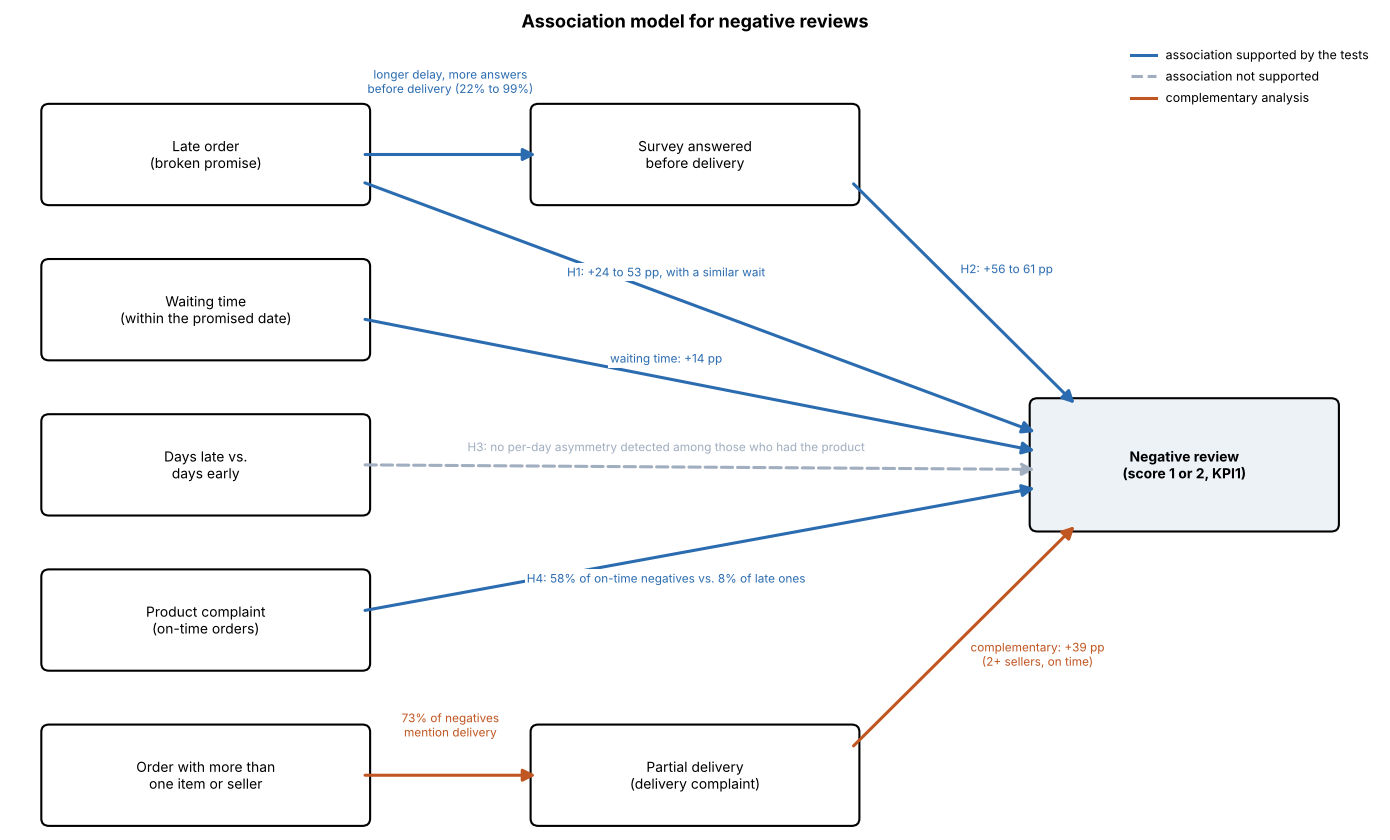

In [31]:
COR_SUSTENTADA = '#2b6cb0'
COR_NAO_SUSTENTADA = '#a0aec0'
COR_COMPLEMENTAR = '#c05621'

fig, eixo = plt.subplots(figsize=(14, 8.5))
eixo.set_xlim(0, 14)
eixo.set_ylim(0, 8.7)
eixo.axis('off')


def desenhar_caixa(x, y, texto, largura=3.2, altura=0.95, cor_fundo='white', negrito=False):
    eixo.add_patch(FancyBboxPatch((x - largura / 2, y - altura / 2), largura, altura,
                                  boxstyle='round,pad=0.08', linewidth=1.5,
                                  edgecolor='black', facecolor=cor_fundo))
    eixo.text(x, y, texto, ha='center', va='center', fontsize=10,
              fontweight='bold' if negrito else 'normal')


def desenhar_seta(origem, destino, rotulo, cor, tracejada=False, posicao=0.5, deslocamento=(0, 0.22)):
    eixo.annotate('', xy=destino, xytext=origem,
                  arrowprops=dict(arrowstyle='-|>', color=cor, linewidth=2.2,
                                  linestyle='--' if tracejada else '-', mutation_scale=18))
    x = origem[0] + (destino[0] - origem[0]) * posicao + deslocamento[0]
    y = origem[1] + (destino[1] - origem[1]) * posicao + deslocamento[1]
    eixo.text(x, y, rotulo, ha='center', va='center', fontsize=8.5, color=cor,
              bbox=dict(facecolor='white', edgecolor='none', pad=1.5))


# Factors observed in the order
desenhar_caixa(2.0, 7.4, 'Late order\n(broken promise)')
desenhar_caixa(2.0, 5.7, 'Waiting time\n(within the promised date)')
desenhar_caixa(2.0, 4.0, 'Days late vs.\ndays early')
desenhar_caixa(2.0, 2.3, 'Product complaint\n(on-time orders)')
desenhar_caixa(2.0, 0.6, 'Order with more than\none item or seller')

# Intermediate mechanisms
desenhar_caixa(7.0, 7.4, 'Survey answered\nbefore delivery')
desenhar_caixa(7.0, 0.6, 'Partial delivery\n(delivery complaint)')

# Main indicator
desenhar_caixa(12.0, 4.0, 'Negative review\n(score 1 or 2, KPI1)', largura=3.0, altura=1.3,
               cor_fundo='#edf2f7', negrito=True)

# Supported associations
desenhar_seta((3.6, 7.4), (5.4, 7.4), 'longer delay, more answers\nbefore delivery (22% to 99%)',
              COR_SUSTENTADA, deslocamento=(0, 0.8))
desenhar_seta((8.6, 7.1), (10.9, 4.65), 'H2: +56 to 61 pp', COR_SUSTENTADA, posicao=0.45, deslocamento=(0.55, 0.15))
desenhar_seta((3.6, 7.1), (10.5, 4.35), 'H1: +24 to 53 pp, with a similar wait', COR_SUSTENTADA,
              posicao=0.45, deslocamento=(0, 0.25))
desenhar_seta((3.6, 5.6), (10.5, 4.15), 'waiting time: +14 pp', COR_SUSTENTADA, posicao=0.45)
desenhar_seta((3.6, 2.4), (10.5, 3.75), 'H4: 58% of on-time negatives vs. 8% of late ones', COR_SUSTENTADA,
              posicao=0.45, deslocamento=(0, -0.25))

# Association not supported
desenhar_seta((3.6, 4.0), (10.5, 3.95), 'H3: no per-day asymmetry detected among those who had the product',
              COR_NAO_SUSTENTADA, tracejada=True, posicao=0.45)

# Complementary analysis
desenhar_seta((3.6, 0.6), (5.4, 0.6), '73% of negatives\nmention delivery', COR_COMPLEMENTAR, deslocamento=(0, 0.55))
desenhar_seta((8.6, 0.9), (10.9, 3.35), 'complementary: +39 pp\n(2+ sellers, on time)', COR_COMPLEMENTAR,
              deslocamento=(0.75, -0.2))

# Legend
eixo.plot([], [], color=COR_SUSTENTADA, linewidth=2.2, label='association supported by the tests')
eixo.plot([], [], color=COR_NAO_SUSTENTADA, linewidth=2.2, linestyle='--', label='association not supported')
eixo.plot([], [], color=COR_COMPLEMENTAR, linewidth=2.2, label='complementary analysis')
eixo.legend(loc='upper right', fontsize=9, frameon=False)

eixo.set_title('Association model for negative reviews', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

The project question was what explains negative reviews at Olist and where the company can act to stand out in customer experience. The results point to **three distinct sources of dissatisfaction**, with different owners and solutions.

**1. Delay reviewed before delivery.** In the full table, delay is the factor most associated with negative reviews (62.4% negative reviews among late orders), and the effect goes beyond waiting time, as predicted by the expectation disconfirmation model (Oliver, 1980). The analysis of H2 and H3, however, shows that most of this effect is concentrated in a specific group: customers who receive the satisfaction survey, sent on the estimated date, before receiving the product. They review a purchase that has not arrived yet, and about 80% give a score of 1 or 2. Among late customers who review with the product in hand, the review is much less negative, and one more day of delay is not associated with a detectable additional drop. The score of late orders therefore largely measures the frustration of people who are still waiting.

**2. The product, in simple orders delivered on time.** When delivery works, dissatisfaction comes from what was received: defects, lower quality than expected or a mismatch with the listing. According to the manual reading, more than half of the negative reviews of on-time orders complain about the product. This problem depends on the platform's sellers and on listing accuracy, not on logistics. Section 3.5 points to categories where this pattern seems stronger, such as `moveis_escritorio` (office furniture), `cama_mesa_banho` (bed, bath and table) and `informatica_acessorios` (computer accessories).

**3. Fragmented delivery of orders with more than one item or seller.** These orders represent about 10% of on-time orders, but account for about 27% of this group's negative reviews, and most of their negative comments are about delivery. Since the dataset records a single delivery date per order, some of them may be recorded as delivered on time without all items having arrived. In that case, the delay indicator underestimates the problem precisely in the most complex orders.

**What the data show and what they only suggest.** All results are associations in observational data. The dataset does not show that sending the survey early *causes* worse reviews, or that improving listings *reduces* complaints. These causal relationships are working hypotheses, and the recommendations below show how to test them.

### 5.3 Recommendations

**R1. Send the satisfaction survey after delivery is confirmed, not on the estimated date.**
*Basis:* H2 and H3. *Source addressed:* 1.

This is the recommendation with the greatest potential impact on the indicator and the lowest operating cost. It should be validated with an A/B test before adoption:

- **Unit:** late orders, randomly assigned to two groups.
- **Control:** survey sent on the estimated date, as today.
- **Treatment:** survey sent only after delivery is confirmed.
- **Primary metric:** negative review rate (KPI1). **Secondary metrics:** average score and survey response rate.
- **Sample size:** to detect a 10 pp reduction from the observed rate of 62.4%, with α = 5% and 80% power, about 385 late orders per group are needed. At the dataset's volume (about 320 late orders per month), this corresponds to roughly 2.5 months of testing.

A management caveat: this change makes the indicator a more faithful measure of the product experience, but it does not reduce delays. The dissatisfaction of customers who wait still exists and needs to be addressed by R2.

**R2. Communicate delays proactively, before the promised date.**
*Basis:* H1. *Source addressed:* 1.

If dissatisfaction comes from the broken promise, warning the customer in advance and offering a new date is a way to reset the expectation before it is frustrated. The effectiveness of this communication cannot be measured with this dataset and should also be tested with an A/B test, with the same primary metric as R1.

**R3. Prioritize logistics on the routes with the most delays.**
*Basis:* section 3.4 and H1. *Source addressed:* 1.

Alagoas, Maranhão and Sergipe have late rates between 15% and 21%, and Rio de Janeiro combines high volume (12,172 orders) with 12% delays. Reviewing carriers and promised dates on these routes is the most direct way to reduce the problem at the source. Lengthening the promised date would also reduce delays, but it may affect sales conversion, so this alternative requires its own analysis.

**R4. Treat orders with more than one seller as a separate operational case.**
*Basis:* section 4.5. *Source addressed:* 3.

Three fronts: record the delivery date per item, not per order, so that the delay indicator reflects the real experience; tell the customer, at purchase, that the order will arrive in more than one delivery; and send the satisfaction survey only after the last item arrives.

**R5. Monitor product complaints by seller and by category.**
*Basis:* H4 and section 3.5. *Source addressed:* 2.

The comment classification developed in this project, with 94% precision, can be used as an early-warning indicator for sellers with a high rate of product complaints. Before operational use, the recall (48%) needs to be improved, by expanding the term list and validating the result on a new sample, independent of the one used here.

### 5.4 Limitations

- **Observational data:** the results indicate association, not causation. The suggested causal relationships should be validated with experiments (R1 and R2).
- **Period:** the dataset covers purchases from January 2017 to August 2018. Olist's operation may have changed since then.
- **Choice of response timing (H2 and H3):** customers decide when to answer the survey. More dissatisfied customers may answer faster, which may widen the difference observed in H2.
- **Volume in the H3 subset:** among those who reviewed after delivery, the late side has little volume. A moderate asymmetry, of the order predicted by the loss aversion literature (Tversky and Kahneman, 1992), cannot be ruled out.
- **Comment classification (H4):** the 48% recall makes the automatic rates a lower bound. The validation sample has 100 comments, and the manual reading was done by a single person.
- **Delivery records:** the dataset has a single delivery date per order, which may underestimate delays in orders with more than one seller.
- **Fashion:** the volume of apparel orders in the dataset is too small for conclusions about the segment, except for `fashion_bolsas_e_acessorios` (bags and accessories).

## 6. Deliverables and sources

### 6.1 Project deliverables

- **Analysis notebook:** this file (the original Portuguese version is in the `pt/` folder).
- **Data (`dados/`):** the 7 Olist tables used in the analysis, as compressed CSV.
- **Manual validation sample (`validacao_h4_amostra.csv`):** 100 manually classified comments, used in section 4.4.
- **Interactive dashboard (Tableau Public):** https://public.tableau.com/views/OlistExperinciadoclienteeavaliaonegativa/PainelOlist
- **Results presentation (PDF):** included in the project folder.

### 6.2 Data

- Olist. *Brazilian E-Commerce Public Dataset by Olist*. Kaggle. Available at: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

### 6.3 Theoretical references

- Kahneman, D.; Tversky, A. (1979). Prospect theory: an analysis of decision under risk. *Econometrica*, 47(2), 263-291.
- Oliver, R. L. (1980). A cognitive model of the antecedents and consequences of satisfaction decisions. *Journal of Marketing Research*, 17(4), 460-469.
- Tversky, A.; Kahneman, D. (1992). Advances in prospect theory: cumulative representation of uncertainty. *Journal of Risk and Uncertainty*, 5(4), 297-323.
- Dunn, O. J. (1961). Multiple comparisons among means. *Journal of the American Statistical Association*, 56(293), 52-64.

### 6.4 Technical documentation

- pandas: https://pandas.pydata.org/docs/
- SciPy, `scipy.stats` module (`mannwhitneyu`, `fisher_exact`, `linregress`, `norm`): https://docs.scipy.org/doc/scipy/reference/stats.html
- Matplotlib: https://matplotlib.org/stable/
- Python, `unicodedata` module: https://docs.python.org/3/library/unicodedata.html
- Tableau Public: https://public.tableau.com

### 6.5 Table exported for the dashboard

To make sure the dashboard shows the same numbers as this notebook, the final table, already prepared and with the time cutoff applied, is exported to a CSV file used as the data source in Tableau Public. Each row is one order. Binary variables are written as 0 and 1, so the mean of each one is directly the indicator's rate. The comment classification columns are only filled for negative reviews with a comment and are empty for other orders. The column names are kept in Portuguese, as in the published dashboard.

In [32]:
ARQUIVO_DASHBOARD = 'base_dashboard_olist.csv'

REGIOES = {
    'Norte': ['AC', 'AM', 'AP', 'PA', 'RO', 'RR', 'TO'],
    'Nordeste': ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'],
    'Centro-Oeste': ['DF', 'GO', 'MS', 'MT'],
    'Sudeste': ['ES', 'MG', 'RJ', 'SP'],
    'Sul': ['PR', 'RS', 'SC']
}
ESTADO_PARA_REGIAO = {estado: regiao for regiao, estados in REGIOES.items() for estado in estados}

base_dashboard = pd.DataFrame({
    'order_id': base['order_id'],
    'data_compra': base['order_purchase_timestamp'].dt.date,
    'mes_compra': base['mes_compra'].dt.to_timestamp().dt.date,
    'estado': base['customer_state'],
    'regiao': base['customer_state'].map(ESTADO_PARA_REGIAO),
    'categoria': base['product_category_name'].fillna('sem categoria'),
    'composicao_pedido': base['composicao_pedido'],
    'nota': base['review_score'],
    'avaliacao_negativa': base['avaliacao_negativa'].astype(int),
    'fora_do_prazo': base['fora_do_prazo'].astype(int),
    'avaliacao_antes_da_entrega': base['avaliacao_antes_da_entrega'].astype(int),
    'tempo_entrega_dias': base['tempo_entrega_dias'].round(2),
    'diferenca_prazo_dias': base['diferenca_prazo_dias'],
    'faixa_tempo_entrega': base['faixa_tempo_entrega'].astype(str),
    'tem_comentario': base['review_comment_message'].notna().astype(int)
})

# Comment classification: only filled for negative reviews with a comment
for coluna in ['reclamacao_produto', 'reclamacao_entrega']:
    base_dashboard[coluna] = negativas_com_comentario[coluna].reindex(base_dashboard.index).astype('Int64')

base_dashboard.to_csv(ARQUIVO_DASHBOARD, index=False)

print('Rows exported:', len(base_dashboard))
print('Columns:', base_dashboard.shape[1])
print('States without a region:', base_dashboard['regiao'].isna().sum())
print()
print('Check against the notebook:')
print(f"   Negative review rate (KPI1): {base_dashboard['avaliacao_negativa'].mean():.1%}")
print(f"   Average score (KPI2): {base_dashboard['nota'].mean():.2f}")
print(f"   Late order rate (KPI5): {base_dashboard['fora_do_prazo'].mean():.1%}")
print(f"   Product complaints among negatives with a comment (KPI8): {base_dashboard['reclamacao_produto'].mean():.1%}")
print('File saved:', ARQUIVO_DASHBOARD)

Rows exported: 95560
Columns: 17
States without a region: 0

Check against the notebook:
   Negative review rate (KPI1): 12.8%
   Average score (KPI2): 4.16
   Late order rate (KPI5): 6.7%
   Product complaints among negatives with a comment (KPI8): 27.8%
File saved: base_dashboard_olist.csv
